<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-03/lab-013b-cnn-jax.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 013b <br>
**Reading:** Lecture Notes, Chapter 2 (*Fundamentals of Deep Learning*), Section *Convolutional Neural Networks*
<hr/>

# Lab 013b — CNNs on MNIST and CIFAR-10 in JAX

This notebook accompanies the lecture on convolutional neural networks (CNNs). Lab 013a does exactly the same in PyTorch; the two notebooks have identical sections, so they can be read side by side. This lab uses JAX (array computing with automatic differentiation and compilation by XLA, Accelerated Linear Algebra), the neural-network library Flax in its `flax.nnx` interface, and the optimisers of Optax. The data are two classic image collections: MNIST (Modified National Institute of Standards and Technology handwritten digits) and CIFAR-10 (Canadian Institute For Advanced Research, 10 classes of small colour photographs).

We begin with the operations a convolutional layer is made of (convolution, padding, stride, pooling and channels), computed with explicit loops and compared with the library. We then train networks of growing size: a dense network and a small CNN on CIFAR-10, a CNN on MNIST, and a larger CIFAR-10 CNN that overfits, together with the same network regularised. With trained networks at hand we open them up: we extract the kernels of a layer and analyse them, look at feature maps, find the images and classes that activate a channel, and compute class activation maps. The notebook closes with transfer learning from CIFAR-10 to MNIST and a table of PyTorch and JAX equivalents.

Everything runs on the CPU (central processing unit). To keep the run time near a quarter of an hour, every network is trained for a few epochs only. The accuracies quoted on the slides come from longer training in Keras; the measured numbers of this notebook are printed next to them.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order*: later cells use variables defined earlier.
> 3. `numpy`, `matplotlib`, `jax`, `flax` and `optax` are pre-installed in Colab. If `flax.nnx` is missing (old Flax), run `!pip install -U flax optax` and restart the session.
> 4. MNIST and CIFAR-10 are downloaded once from the official sources (about 12 MB for MNIST, 163 MB for CIFAR-10) and reused on later runs.
> 5. Trained weights are saved and reused on later runs.
> 6. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

## 0. The data sets

The first cell tells JAX to use the CPU and hides every graphics card. This must happen before `jax` is imported.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # JAX: CPU backend only
os.environ["CUDA_VISIBLE_DEVICES"] = ""      # no graphics card visible to any framework

import time, gzip, pickle, tarfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import optax
import flax
from flax import nnx
import flax.serialization

rng = np.random.default_rng(0)                  # NumPy generator: subsets, mini-batch order, chosen images

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

DATA, RESULTS = "data", "results"
os.makedirs(DATA, exist_ok=True); os.makedirs(RESULTS, exist_ok=True)
T_START = time.time()
print("JAX", jax.__version__, "| Flax", flax.__version__, "| Optax", optax.__version__, "| NumPy", np.__version__,
      "| devices:", jax.devices())

JAX 0.11.0 | Flax 0.12.8 | Optax 0.2.6 | NumPy 2.1.3 | devices: [CpuDevice(id=0)]


### MNIST

MNIST (Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, *Gradient-based learning applied to document recognition*, *Proc. IEEE* **86**, 2278 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)) contains $70\,000$ greyscale images of handwritten digits, $60\,000$ for training and $10\,000$ for testing. One sample is a $28\times28$ image whose pixel values $0\dots255$ give the ink intensity on a black background; its label is the digit $0,\dots,9$. One image per class is shown at the end of this section.

MNIST is stored in the IDX format: a short header (a "magic number" whose 4th byte is the number of dimensions, then the size of each dimension as a big-endian 32-bit integer) followed by the raw bytes. We read it with NumPy: first from local copies, otherwise from two public mirrors of the original files.

Shapes: training images $(60000, 28, 28)$, test images $(10000, 28, 28)$, pixel values scaled to $[0,1]$; labels are integers $0,\dots,9$.

In [2]:
RAW = os.path.join(DATA, "MNIST_raw"); os.makedirs(RAW, exist_ok=True)
MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/", "https://storage.googleapis.com/cvdf-datasets/mnist/"]

def mnist_file(name):
    # return the bytes of one MNIST file: the local copy first, then the mirrors
    p = os.path.join(RAW, name)
    if os.path.exists(p): return open(p, "rb").read()
    if os.path.exists(p + ".gz"): return gzip.open(p + ".gz").read()
    for m in MIRRORS:
        try:
            urllib.request.urlretrieve(m + name + ".gz", os.path.join(RAW, name + ".gz"))
            return gzip.open(os.path.join(RAW, name + ".gz")).read()
        except Exception: pass
    raise RuntimeError("MNIST could not be found or downloaded")

def idx(name):
    # decode an IDX file: images -> (n, rows, cols) uint8, labels -> (n,) uint8
    d = mnist_file(name)
    if d[3] == 3:
        n, r, c = np.frombuffer(d[4:16], ">i4")
        return np.frombuffer(d[16:], np.uint8).reshape(n, r, c)
    return np.frombuffer(d[8:], np.uint8)

Xm_tr = idx("train-images-idx3-ubyte").astype(np.float32) / 255; ym_tr = idx("train-labels-idx1-ubyte").astype(np.int32)
Xm_te = idx("t10k-images-idx3-ubyte").astype(np.float32) / 255;  ym_te = idx("t10k-labels-idx1-ubyte").astype(np.int32)
assert Xm_tr.shape == (60000, 28, 28) and Xm_te.shape == (10000, 28, 28)
print("MNIST training:", Xm_tr.shape, " test:", Xm_te.shape, " pixel range:", Xm_tr.min(), Xm_tr.max())

MNIST training: (60000, 28, 28)  test: (10000, 28, 28)  pixel range: 0.0 1.0


### CIFAR-10

CIFAR-10 (A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, technical report, University of Toronto, 2009, [PDF](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf)) contains $60\,000$ colour photographs of $32\times32$ pixels, $50\,000$ for training and $10\,000$ for testing, $6000$ per class. One sample holds three numbers per pixel, the red, green and blue intensities $0\dots255$; its label is one of ten classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck.

CIFAR-10 in the "python version" is a set of pickled batches: each holds `data`, an array of shape $(10000, 3072)$ of bytes (first the 1024 red values of a $32\times32$ image, then 1024 green, then 1024 blue), and `labels`. The archive is downloaded once from the authors' page, <https://www.cs.toronto.edu/~kriz/cifar.html>.

We keep the raw images as `uint8` arrays of shape $(N, 32, 32, 3)$ (height, width, channel), convenient for plotting.

In [3]:
CIFAR_URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"

def cifar_dir():
    d = os.path.join(DATA, "cifar-10-batches-py")
    if os.path.exists(os.path.join(d, "test_batch")): return d
    tgz = os.path.join(DATA, "cifar-10-python.tar.gz")
    print("downloading CIFAR-10 (163 MB) ...")
    urllib.request.urlretrieve(CIFAR_URL, tgz)
    with tarfile.open(tgz) as t: t.extractall(DATA, filter="data")
    return os.path.join(DATA, "cifar-10-batches-py")

def load_batch(d, name):
    with open(os.path.join(d, name), "rb") as f:
        b = pickle.load(f, encoding="bytes")
    X = b[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)      # (N, 3, 32, 32) -> (N, 32, 32, 3)
    return X, np.array(b[b"labels"], dtype=np.int32)

D_CIFAR = cifar_dir()
parts = [load_batch(D_CIFAR, f"data_batch_{i}") for i in range(1, 6)]
Xc_tr_raw = np.concatenate([p[0] for p in parts]); yc_tr = np.concatenate([p[1] for p in parts])
Xc_te_raw, yc_te = load_batch(D_CIFAR, "test_batch")
with open(os.path.join(D_CIFAR, "batches.meta"), "rb") as f:
    CLASSES = [c.decode() for c in pickle.load(f, encoding="bytes")[b"label_names"]]
assert Xc_tr_raw.shape == (50000, 32, 32, 3) and Xc_te_raw.shape == (10000, 32, 32, 3)
print("CIFAR-10 from", D_CIFAR, "| training:", Xc_tr_raw.shape, " test:", Xc_te_raw.shape)
print("classes:", CLASSES)

CIFAR-10 from data/cifar-10-batches-py | training: (50000, 32, 32, 3)  test: (10000, 32, 32, 3)
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


For training, each colour channel is standardised with the mean $\mu_c$ and standard deviation $\sigma_c$ of the training set,
$$x \leftarrow \frac{x/255 - \mu_c}{\sigma_c}. \tag{1}$$
Flax uses the layout $(N, H, W, C)$: number of images, height, width, channels (channels last), so the arrays keep the layout of the raw images. The data stay NumPy arrays; each mini-batch is converted to a JAX array when it enters a compiled function.

In [4]:
CIFAR_MEAN = (Xc_tr_raw / 255.0).mean(axis=(0, 1, 2)).astype(np.float32)   # (3,) one number per channel
CIFAR_STD  = (Xc_tr_raw / 255.0).std(axis=(0, 1, 2)).astype(np.float32)    # (3,)

def cifar_array(X_raw):
    # uint8 (N, 32, 32, 3) -> standardised float32 (N, 32, 32, 3)
    return ((X_raw.astype(np.float32) / 255 - CIFAR_MEAN) / CIFAR_STD).astype(np.float32)

Xc_tr, Xc_te = cifar_array(Xc_tr_raw), cifar_array(Xc_te_raw)
Xm_tr4, Xm_te4 = Xm_tr[..., None], Xm_te[..., None]          # (N, 28, 28, 1)
print("channel means:", CIFAR_MEAN.round(3), " standard deviations:", CIFAR_STD.round(3))
print("Xc_tr", Xc_tr.shape, " Xm_tr4", Xm_tr4.shape)

channel means: [0.491 0.482 0.447]  standard deviations: [0.247 0.243 0.262]
Xc_tr (50000, 32, 32, 3)  Xm_tr4 (60000, 28, 28, 1)


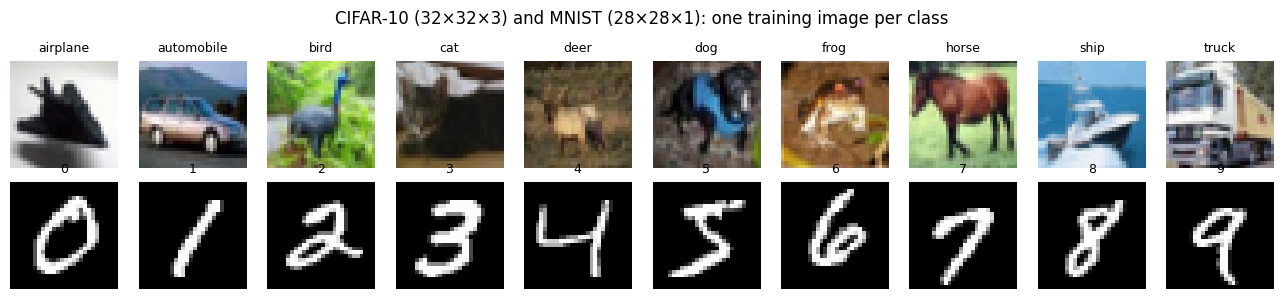

In [5]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for c in range(10):
    i = np.flatnonzero(yc_tr == c)[0]; axes[0, c].imshow(Xc_tr_raw[i]); axes[0, c].set_title(CLASSES[c], fontsize=9)
    j = np.flatnonzero(ym_tr == c)[0]; axes[1, c].imshow(Xm_tr[j], cmap="gray"); axes[1, c].set_title(str(c), fontsize=9)
for a in axes.ravel(): a.axis("off")
fig.suptitle("CIFAR-10 (32×32×3) and MNIST (28×28×1): one training image per class"); plt.tight_layout(); plt.show()

## 1. Convolution, padding, stride, pooling and channels

### 1.1 Discrete convolution in one dimension

For a signal $x[n]$ and a kernel $g[m]$ with $K$ entries, the discrete convolution is
$$(x*g)[n] = \sum_{m=0}^{K-1} g[m]\,x[n-m]. \tag{2}$$
We keep only the outputs for which the kernel lies completely inside the signal ("valid" mode): for a signal of length $L$ there are $L-K+1$ of them. Two kernels from the lecture: the difference $g=(1,0,-1)$ (large where the signal changes, zero where it is flat) and the moving average $g=(\tfrac13,\tfrac13,\tfrac13)$.

Layers of neural networks compute instead the **cross-correlation**
$$\sum_{m=0}^{K-1} g[m]\,x[n+m], \tag{3}$$
which is the convolution with the flipped kernel. We check both relations against NumPy and against `jax.lax.conv_general_dilated`, the general convolution of JAX. Its `dimension_numbers=("NWC", "WIO", "NWC")` say that the input is (batch, width, channels), the kernel (width, input channels, output channels) and the output again (batch, width, channels).

In [6]:
x1 = np.array([0, 0, 1, 2, 3, 3, 3, 2, 1, 0, 0], dtype=np.float32)    # signal, length L = 11
g_diff = np.array([1, 0, -1], dtype=np.float32)                         # difference kernel
g_avg = np.ones(3, dtype=np.float32) / 3                                # moving average

def conv1d_loops(x, g):
    # valid convolution (x*g)[n] = sum_m g[m] x[n-m], for n = K-1, ..., L-1
    K, L = len(g), len(x)
    out = np.zeros(L - K + 1, dtype=np.float32)
    for n in range(K - 1, L):
        for m in range(K):
            out[n - K + 1] += g[m] * x[n - m]
    return out

def lax_xcorr1d(x, g):
    # cross-correlation with JAX: input (1, L, 1), kernel (K, 1, 1)
    return jax.lax.conv_general_dilated(jnp.asarray(x)[None, :, None], jnp.asarray(g)[:, None, None], window_strides=(1,),
                                        padding="VALID", dimension_numbers=("NWC", "WIO", "NWC"))[0, :, 0]

for name, g in [("difference", g_diff), ("moving average", g_avg)]:
    y_loop = conv1d_loops(x1, g)
    y_np = np.convolve(x1, g, mode="valid")                    # true convolution
    y_jax = np.asarray(lax_xcorr1d(x1, g[::-1].copy()))        # cross-correlation with the flipped kernel
    assert np.allclose(y_loop, y_np, atol=1e-6) and np.allclose(y_loop, y_jax, atol=1e-6)
    print(f"{name:15s}", np.round(y_loop, 3))

# the lax convolution with the kernel as it is computes the cross-correlation
xcorr = np.asarray(lax_xcorr1d(x1, g_diff))
assert np.allclose(xcorr, np.correlate(x1, g_diff, mode="valid")) and np.allclose(xcorr, -conv1d_loops(x1, g_diff))
print("cross-correlation with (1,0,-1):", xcorr, " = minus the convolution, because this kernel is antisymmetric")

difference      [ 1.  2.  2.  1.  0. -1. -2. -2. -1.]
moving average  [0.333 1.    2.    2.667 3.    2.667 2.    1.    0.333]
cross-correlation with (1,0,-1): [-1. -2. -2. -1.  0.  1.  2.  2.  1.]  = minus the convolution, because this kernel is antisymmetric


The difference kernel gives $+2$ on the rising flank and $-2$ on the falling flank of the plateau, and $0$ on the plateau itself: it detects changes. The moving average returns a smoother copy of the signal. For the antisymmetric kernel $(1,0,-1)$, flipping changes the sign, so the cross-correlation is minus the convolution; for the symmetric averaging kernel both are equal.

### 1.2 Discrete convolution of an image with Sobel kernels

For an image $x(i,j)$ and a $k\times k$ kernel $G(m,n)$, a convolutional layer computes the cross-correlation
$$S(i,j) = \sum_{m=0}^{k-1}\sum_{n=0}^{k-1} G(m,n)\,x(i\,s+m,\; j\,s+n), \tag{4}$$
where $x$ has first been padded with $P$ rows and columns of zeros on each side, and $s$ is the stride. We use the Sobel kernels of the lecture,
$$G_x = \begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix},\qquad G_y=\begin{bmatrix}1&2&1\\0&0&0\\-1&-2&-1\end{bmatrix}, \tag{5}$$
on one MNIST digit of shape $(28,28)$, with $P=1$, $s=1$; the output then has shape $(28,28)$. With `dimension_numbers=("NHWC", "HWIO", "NHWC")`, `jax.lax.conv_general_dilated` takes the input as $(N, H, W, C_{\text{in}}) = (1,28,28,1)$ and the kernel as $(k, k, C_{\text{in}}, C_{\text{out}}) = (3,3,1,2)$ (both Sobel kernels at once).

In [7]:
GX = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)    # Sobel x: vertical edges
GY = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], dtype=np.float32)    # Sobel y: horizontal edges

def xcorr2d_loops(x, G, P=0, s=1):
    # S(i,j) = sum_{m,n} G(m,n) x_pad(i*s+m, j*s+n), one input channel, one kernel
    k = G.shape[0]
    xp = np.pad(x, P)                                   # P zeros on every side
    O = (x.shape[0] - k + 2 * P) // s + 1               # output size (square input)
    S = np.zeros((O, O), dtype=np.float32)
    for i in range(O):
        for j in range(O):
            for m in range(k):
                for n in range(k):
                    S[i, j] += G[m, n] * xp[i * s + m, j * s + n]
    return S

def lax_conv2d(x, w, P=0, s=1):
    # x: (N, H, W, C_in), w: (k, k, C_in, C_out) -> (N, O, O, C_out)
    return jax.lax.conv_general_dilated(jnp.asarray(x), jnp.asarray(w), window_strides=(s, s), padding=[(P, P), (P, P)],
                                        dimension_numbers=("NHWC", "HWIO", "NHWC"))

digit = Xm_tr[0]                                        # (28, 28), the label is 5
Sx, Sy = xcorr2d_loops(digit, GX, P=1), xcorr2d_loops(digit, GY, P=1)
lib = np.asarray(lax_conv2d(digit[None, :, :, None], np.stack([GX, GY], axis=-1)[:, :, None, :], P=1))[0]   # (28, 28, 2)
assert Sx.shape == (28, 28) and np.allclose(Sx, lib[..., 0], atol=1e-5) and np.allclose(Sy, lib[..., 1], atol=1e-5)
print("loops and lax.conv_general_dilated agree; max |S_x| =", np.abs(Sx).max().round(2), " max |S_y| =", np.abs(Sy).max().round(2))

loops and lax.conv_general_dilated agree; max |S_x| = 3.92  max |S_y| = 3.97


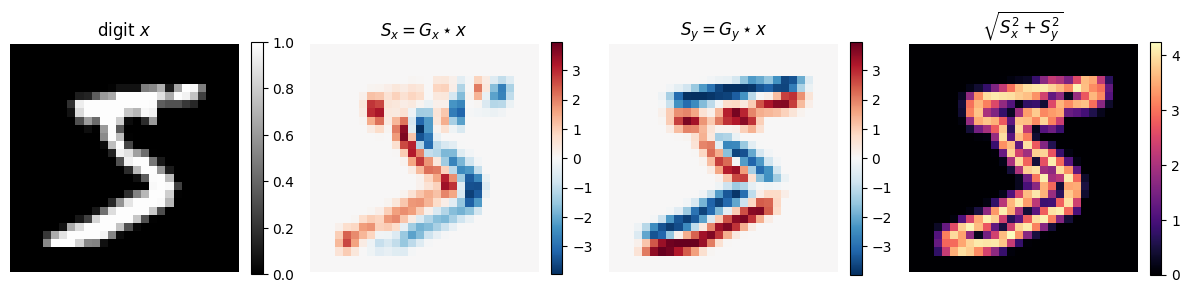

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
v = np.abs(np.stack([Sx, Sy])).max()
for a, img, t, cm, lim in [(axes[0], digit, "digit $x$", "gray", None), (axes[1], Sx, "$S_x = G_x \\star x$", "RdBu_r", v),
                           (axes[2], Sy, "$S_y = G_y \\star x$", "RdBu_r", v), (axes[3], np.hypot(Sx, Sy), "$\\sqrt{S_x^2+S_y^2}$", "magma", None)]:
    im = a.imshow(img, cmap=cm, vmin=-lim if lim else None, vmax=lim); a.set_title(t); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

$S_x$ is positive (red) on the left flank of every vertical stroke, where the intensity rises from left to right, and negative (blue) on the right flank; $S_y$ does the same for horizontal strokes, with the sign set by whether the top or the bottom is brighter. The magnitude $\sqrt{S_x^2+S_y^2}$ outlines the digit: an edge map. Inside the strokes and in the background the image is flat and both responses vanish.

### 1.3 Output size

Along one dimension, an input of size $W$, a kernel of size $k$, padding $P$ and stride $s$ give
$$O = \left\lfloor\frac{W-k+2P}{s}\right\rfloor + 1 . \tag{6}$$
We check the formula, and the loop implementation, against `jax.lax.conv_general_dilated` for several $(k, P, s)$ on a random $7\times7$ input and on the CIFAR-10 size $W=32$.

In [9]:
def out_size(W, k, P, s):
    return (W - k + 2 * P) // s + 1

x7 = np.random.default_rng(1).normal(size=(7, 7)).astype(np.float32)
print(" W  k  P  s | formula  lax.conv  loops agree")
for W, k, P, s in [(7, 3, 0, 1), (7, 3, 1, 1), (7, 3, 1, 2), (7, 5, 0, 1), (7, 5, 2, 2), (7, 2, 0, 2), (32, 3, 1, 1), (32, 3, 1, 2), (32, 5, 0, 1)]:
    x = x7 if W == 7 else np.random.default_rng(2).normal(size=(W, W)).astype(np.float32)
    G = np.random.default_rng(3).normal(size=(k, k)).astype(np.float32)
    y = np.asarray(lax_conv2d(x[None, :, :, None], G[:, :, None, None], P=P, s=s))[0, :, :, 0]
    same = np.allclose(xcorr2d_loops(x, G, P, s), y, atol=1e-4)
    assert y.shape == (out_size(W, k, P, s),) * 2 and same
    print(f"{W:2d} {k:2d} {P:2d} {s:2d} | {out_size(W, k, P, s):5d} {y.shape[0]:8d}   {same}")

 W  k  P  s | formula  lax.conv  loops agree
 7  3  0  1 |     5        5   True
 7  3  1  1 |     7        7   True
 7  3  1  2 |     4        4   True
 7  5  0  1 |     3        3   True
 7  5  2  2 |     4        4   True
 7  2  0  2 |     3        3   True
32  3  1  1 |    32       32   True


32  3  1  2 |    16       16   True
32  5  0  1 |    28       28   True


All cases agree. "Same" padding,
$$P=\frac{k-1}{2}, \tag{7}$$
with $s=1$ keeps the size ($32\to32$); stride 2 halves it ($32\to16$); without padding a $k\times k$ kernel removes $k-1$ pixels. When $W-k+2P$ is not divisible by $s$ (e.g. $W=7, k=2, s=2$), the floor drops the last incomplete window.

### 1.4 Max pooling and average pooling

A pooling window $2\times2$ with stride 2 replaces each $2\times2$ block by one number: its maximum or its mean. Global average pooling replaces the whole map by its mean. We use the $4\times4$ example of the lecture. Reshaping $(4,4)\to(2,2,2,2)$ splits the row index into (block row, row inside block) and the column index likewise, so the reduction over axes 1 and 3 acts inside each block. The library functions `nnx.max_pool` and `nnx.avg_pool` take $(N,H,W,C)$ arrays.

In [10]:
A4 = np.array([[1, 3, 2, 4], [5, 6, 7, 8], [4, 2, 1, 3], [9, 8, 6, 5]], dtype=np.float32)
blocks = A4.reshape(2, 2, 2, 2)                       # (block row, row in block, block col, col in block)
max_explicit, avg_explicit, gap_explicit = blocks.max(axis=(1, 3)), blocks.mean(axis=(1, 3)), A4.mean()

t4 = jnp.asarray(A4)[None, :, :, None]                # (1, 4, 4, 1)
max_lib = np.asarray(nnx.max_pool(t4, window_shape=(2, 2), strides=(2, 2)))[0, :, :, 0]
avg_lib = np.asarray(nnx.avg_pool(t4, window_shape=(2, 2), strides=(2, 2)))[0, :, :, 0]
assert np.array_equal(max_explicit, max_lib) and np.allclose(avg_explicit, avg_lib)
assert np.array_equal(max_explicit, [[6, 8], [9, 6]]) and np.allclose(avg_explicit, [[3.75, 5.25], [5.75, 3.75]]) and gap_explicit == 4.625
print("max pooling:\n", max_explicit, "\naverage pooling:\n", avg_explicit, "\nglobal average pooling:", gap_explicit)

max pooling:
 [[6. 8.]
 [9. 6.]] 
average pooling:
 [[3.75 5.25]
 [5.75 3.75]] 
global average pooling: 4.625


The numbers are those of the slide, for the top-left block (maximum and mean) and for the global average:
$$\max(1,3,5,6)=6,\qquad \frac{1+3+5+6}{4}=3.75,\qquad \frac{74}{16}=4.625. \tag{8}$$ Pooling has no trainable parameters.

### 1.5 Channels

A colour image has three numbers per pixel, $x(i,j,c)$ with $c\in\{R,G,B\}$ (red, green, blue). A convolutional layer with $C_{\text{in}}$ input channels and $C_{\text{out}}$ output channels holds $C_{\text{out}}$ kernels of shape $k\times k\times C_{\text{in}}$ and one bias $b_o$ per output channel:
$$S_o(i,j) = \sum_{c=1}^{C_{\text{in}}}\sum_{m,n} W[m,n,c,o]\; x_{\text{pad}}(i+m,\,j+n,\,c) + b_o . \tag{9}$$
In Flax the kernel is stored as $(k_h, k_w, C_{\text{in}}, C_{\text{out}})$. For `nnx.Conv(3, 32, (3, 3))` this gives
$$3\cdot3\cdot3\cdot32 + 32 = 896 \tag{10}$$
parameters, and `padding="SAME"` is $P=1$ for a $3\times3$ kernel. We confirm the count and compare one output value of the layer with the formula evaluated directly.

In [11]:
def count_params(model):
    return sum(x.size for x in jax.tree.leaves(nnx.state(model, nnx.Param)))

img = Xc_tr[0]                                            # (32, 32, 3), standardised
conv = nnx.Conv(in_features=3, out_features=32, kernel_size=(3, 3), padding="SAME", rngs=nnx.Rngs(0))
print("kernel", conv.kernel[...].shape, "= (k, k, C_in, C_out);  bias", conv.bias[...].shape)
n_par = count_params(conv)
assert n_par == 3 * 3 * 3 * 32 + 32 == 896
S = np.asarray(conv(jnp.asarray(img)[None]))[0]           # (32, 32, 32): 32 feature maps of 32x32
o, i, j = 5, 10, 20                                       # one output channel and one position
xp = np.pad(img, ((1, 1), (1, 1), (0, 0)))                # zero padding P = 1
W, b = np.asarray(conv.kernel[...]), np.asarray(conv.bias[...])
explicit = (W[:, :, :, o] * xp[i:i + 3, j:j + 3, :]).sum() + b[o]
assert np.isclose(explicit, S[i, j, o], atol=1e-5)
print("parameters:", n_par, "| output", S.shape, f"| S[{i},{j},{o}] layer = {S[i, j, o]:.5f}, explicit sum = {explicit:.5f}")

kernel (3, 3, 3, 32) = (k, k, C_in, C_out);  bias (32,)
parameters: 896 | output (32, 32, 32) | S[10,20,5] layer = 0.10099, explicit sum = 0.10099


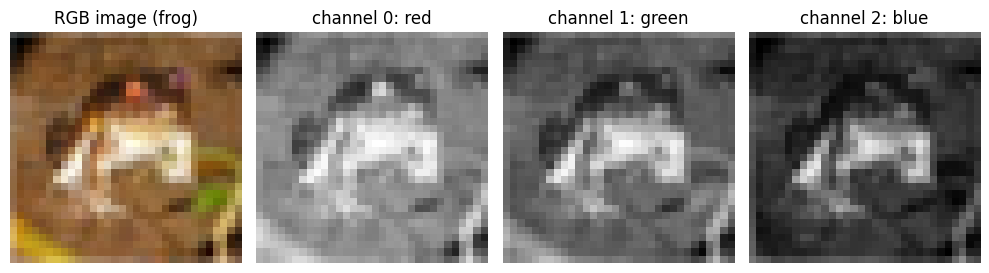

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
axes[0].imshow(Xc_tr_raw[0]); axes[0].set_title(f"RGB image ({CLASSES[yc_tr[0]]})")
for c, (a, name) in enumerate(zip(axes[1:], ["red", "green", "blue"])):
    a.imshow(Xc_tr_raw[0][:, :, c], cmap="gray", vmin=0, vmax=255); a.set_title(f"channel {c}: {name}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

The three channels are three greyscale images of the same scene. The layer sums the contributions of all three channels for each kernel, so 32 kernels give 32 feature maps, whatever the number of input channels. The 896 parameters do not depend on the image size: one kernel is shared by all $32\times32$ positions. A dense layer with 32 outputs on the flattened image would need
$$3072\cdot32+32 = 98\,336. \tag{11}$$

## 2. A dense network and a small CNN on CIFAR-10

### Training and evaluation

The same tools serve every model of this notebook. A Flax `nnx.Module` is a Python object holding its parameters (`nnx.Param`), batch-norm statistics (`nnx.BatchStat`) and random-number streams (for dropout), and `nnx.Optimizer(model, tx, wrt=nnx.Param)` holds the Optax optimiser state for the parameters selected by the filter `wrt`.

One training step is the function `train_step`: it computes the cross-entropy loss and its gradient with `nnx.value_and_grad` and applies one Adam update. `nnx.jit` compiles it with XLA on the first call, so the first mini-batch of every model is slower than the rest. The function `predict` returns the logits (the scores before the softmax) in evaluation mode (`model.eval()`: dropout off, batch norm uses running averages), in batches of 1000 images. The function `train` loops over epochs with mini-batches of 128 images; after each epoch it records the loss and accuracy on the test set and on the first 10 000 training images, both in evaluation mode. To see which classes are mistaken for which, `confusion_matrix` counts $C_{ab}$, the number of test images of true class $a$ predicted as class $b$; the plot shows each row divided by its sum, with the counts shown in the cells.

L2 weight decay is `optax.add_decayed_weights(wd)` before Adam: it adds $\text{wd}\cdot\theta$ to every gradient, the gradient of the penalty
$$\lambda\sum_i\theta_i^2,\qquad \lambda = \frac{\text{wd}}{2}. \tag{12}$$
This is the same as `weight_decay` in `torch.optim.Adam`.

In [13]:
N_EVAL = 10000          # training images used to measure the training accuracy

def loss_fn(model, x, y):
    return optax.softmax_cross_entropy_with_integer_labels(model(x), y).mean()

@nnx.jit
def train_step(model, optimizer, x, y):
    loss, grads = nnx.value_and_grad(loss_fn)(model, x, y)
    optimizer.update(model, grads)                      # Adam update of the parameters selected by optimizer.wrt
    return loss

def augment(x, key, max_shift=4):
    # x: (B, 32, 32, C) -> random left-right flip and random shift by up to max_shift pixels
    k1, k2 = jax.random.split(key)
    B, H, W, C = x.shape
    flip = jax.random.bernoulli(k1, 0.5, (B,))
    x = jnp.where(flip[:, None, None, None], x[:, :, ::-1, :], x)
    xp = jnp.pad(x, ((0, 0), (max_shift, max_shift), (max_shift, max_shift), (0, 0)))   # (B, H+8, W+8, C)
    shift = jax.random.randint(k2, (B, 2), 0, 2 * max_shift + 1)
    crop = lambda im, s: jax.lax.dynamic_slice(im, (s[0], s[1], 0), (H, W, C))
    return jax.vmap(crop)(xp, shift)                                                      # (B, H, W, C)

@nnx.jit
def train_step_aug(model, optimizer, x, y, key):
    return train_step(model, optimizer, augment(x, key), y)

@nnx.jit
def logits_fn(model, x):
    return model(x)

def predict(model, X, batch=1000):
    model.eval()
    return np.concatenate([np.asarray(logits_fn(model, jnp.asarray(X[k:k + batch]))) for k in range(0, len(X), batch)])

def evaluate(model, X, y):
    logits = predict(model, X)
    loss = float(optax.softmax_cross_entropy_with_integer_labels(jnp.asarray(logits), jnp.asarray(y)).mean())
    return loss, float((logits.argmax(1) == y).mean())

def train(model, X, y, Xte, yte, epochs, lr=1e-3, weight_decay=0.0, use_augment=False, batch=128, name="model", seed=0):
    tx = optax.adam(lr) if weight_decay == 0 else optax.chain(optax.add_decayed_weights(weight_decay), optax.adam(lr))
    optimizer = nnx.Optimizer(model, tx, wrt=nnx.Param)
    r, key = np.random.default_rng(seed), jax.random.key(seed)
    hist = {k: [] for k in ("train_loss", "train_acc", "test_loss", "test_acc")}
    t0 = time.time()
    for ep in range(epochs):
        model.train()                                         # dropout on, batch norm uses batch statistics
        perm = r.permutation(len(X))
        for k in range(0, len(X), batch):
            idx = perm[k:k + batch]
            if use_augment:
                key, sub = jax.random.split(key)
                train_step_aug(model, optimizer, jnp.asarray(X[idx]), jnp.asarray(y[idx]), sub)
            else:
                train_step(model, optimizer, jnp.asarray(X[idx]), jnp.asarray(y[idx]))
        for part, (XX, yy) in (("train", (X[:N_EVAL], y[:N_EVAL])), ("test", (Xte, yte))):
            l, a = evaluate(model, XX, yy); hist[part + "_loss"].append(l); hist[part + "_acc"].append(a)
        print(f"{name} epoch {ep + 1}/{epochs}: train acc {hist['train_acc'][-1]:.3f}, test acc {hist['test_acc'][-1]:.3f}, "
              f"test loss {hist['test_loss'][-1]:.3f}  ({time.time() - t0:.0f} s)")
    hist["time"], hist["n_train"] = time.time() - t0, len(X)
    return hist

def confusion_matrix(y_true, y_pred, n=10):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (np.asarray(y_true), np.asarray(y_pred)), 1)
    return cm

def plot_confusion(ax, cm, labels, title):
    frac = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for a in range(len(labels)):
        for b in range(len(labels)):
            ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=6.5, color="white" if frac[a, b] > 0.5 else "black")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, fontsize=7)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9)

def weights_dict(model):
    # parameters and batch-norm statistics as a nested dictionary of NumPy arrays (no random-number state)
    return jax.tree.map(np.asarray, nnx.to_pure_dict(nnx.state(model, (nnx.Param, nnx.BatchStat))))

def save(model, name):
    path = os.path.join(RESULTS, f"Lab_013b_{name}.msgpack")
    with open(path, "wb") as f: f.write(flax.serialization.msgpack_serialize(weights_dict(model)))
    return path

def load(model, path):
    state = nnx.state(model, (nnx.Param, nnx.BatchStat))
    with open(path, "rb") as f: nnx.replace_by_pure_dict(state, flax.serialization.msgpack_restore(f.read()))
    nnx.update(model, state)
    return model

### Two models with the same training budget

The first model is the **dense network** of the slides: the $3072$ inputs ($32\times32$ pixels, 3 colours) are flattened and fed to 21 sigmoid units and then to 10 outputs, which makes
$$3072\cdot21+21+21\cdot10+10 = 64\,753 \tag{13}$$
parameters. The second is the **small CNN** of the slides, except for the activation of the convolution: a convolution $3\to32$ with $3\times3$ kernels and padding "SAME", followed by a rectified linear unit (ReLU, $\max(0,z)$), max pooling $2\times2$, flattening to $8192$ numbers ($16\times16$ positions, 32 channels), 21 sigmoid units and 10 outputs, in total
$$896 + (8192\cdot21+21) + (21\cdot10+10) = 173\,169 \tag{14}$$
parameters.

The slides use a sigmoid after the convolution. With a sigmoid there, our short training stalls: in a test run of Lab 013a (PyTorch, 5 epochs) the test accuracy stayed at 19% (in Lab 013b at 10%), and on 10 000 images a sigmoid convolution with learning rate $10^{-3}$ stayed at chance level for 3 epochs, while the ReLU version reached 45%. A sigmoid layer feeding 8192 inputs into the dense layer learns very slowly at the start; the long Keras training of the slides gets past this phase, a few epochs do not. We therefore use a ReLU in the convolution and keep the sigmoid in the dense hidden layer.

Both are trained with the same optimiser, learning rate, batch size and number of epochs (`EPOCHS_SHORT`). The numbers of epochs of all models are collected at the top of the model cell. Flax and PyTorch initialise the weights with different random distributions (Flax: LeCun normal kernels and zero biases; PyTorch: uniform), so the numbers of Lab 013a and 013b differ slightly.

In [14]:
EPOCHS_SHORT = 3      # dense network and small CNN on CIFAR-10
EPOCHS_MNIST = 2      # CNN on MNIST
EPOCHS_LARGE = 12     # larger CNN and regularised CNN, on N_SUB training images
N_SUB = 10000         # CIFAR-10 training images for the larger and regularised CNN
EPOCHS_GAP = 3        # global-average-pooling CNN for class activation maps
TRANSFER_STEPS = 200  # gradient steps per transfer-learning run

class DenseNet(nnx.Module):
    def __init__(self, rngs):
        self.fc1 = nnx.Linear(3072, 21, rngs=rngs)
        self.fc2 = nnx.Linear(21, 10, rngs=rngs)
    def __call__(self, x):                      # x: (N, 32, 32, 3)
        return self.fc2(nnx.sigmoid(self.fc1(x.reshape(x.shape[0], -1))))

class SmallCNN(nnx.Module):
    def __init__(self, rngs):
        self.conv1 = nnx.Conv(3, 32, (3, 3), padding="SAME", rngs=rngs)
        self.fc1 = nnx.Linear(16 * 16 * 32, 21, rngs=rngs)
        self.fc2 = nnx.Linear(21, 10, rngs=rngs)
    def __call__(self, x):                      # (N,32,32,3) -> (N,32,32,32) -> (N,16,16,32) -> (N,8192) -> (N,21) -> (N,10)
        h = nnx.max_pool(nnx.relu(self.conv1(x)), (2, 2), strides=(2, 2))
        return self.fc2(nnx.sigmoid(self.fc1(h.reshape(h.shape[0], -1))))

dense, small = DenseNet(nnx.Rngs(0)), SmallCNN(nnx.Rngs(0))
assert count_params(dense) == 64753 and count_params(small) == 173169
assert small(jnp.asarray(Xc_tr[:2])).shape == (2, 10)
print("parameters: dense", count_params(dense), " small CNN", count_params(small))

parameters: dense 64753  small CNN 173169


### Model architectures

A diagram of the layers makes the layer sizes and parameter counts of the two models visible. We use a drawing function of our own and the summary table that Flax computes from an `nnx` model; both return for the larger networks later on.

The function `draw_network` draws a fully connected network as it is usually sketched on a blackboard. Each layer is a column of circles, one per neuron, and thin grey lines join every neuron to every neuron of the next layer, since a dense layer connects all of them. A layer with more than `max_nodes` neurons is shown by its first and last few neurons with a vertical ellipsis in between, and its true size is written under the column. The height of a column grows with the logarithm of the layer size, so a wide layer is visibly taller than a narrow one. Input and output layers are grey and hidden layers blue; orange is reserved for a latent layer and green for an additional input such as a class label.

For a network of your own, pass the layer sizes from the input to the output, e.g. `draw_network([784, 128, 10])`; `labels`, `colors` and `groups` (brackets over ranges of columns) are optional, and `ax=` draws into a panel of an existing figure. An entry of the list may itself be a list of sizes: the column then holds several blocks, which is how two inputs entering the same layer are drawn. Only dense layers can be drawn this way. A convolutional layer is a set of small kernels shared by all positions of the image, not a column of independent neurons, so the convolutional part of a network is left to the library tools further below.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Colours used for the network drawings: grey for the data (input and output),
# blue for hidden layers, orange for the latent (bottleneck) layer and green
# for an extra conditioning input such as a one-hot class label.
GREY, BLUE, ORANGE, GREEN = "#8C8C8C", "#005CA7", "#EB6709", "#2E8B57"


def draw_network(layer_sizes, labels=None, colors=None, max_nodes=10,
                 groups=None, no_input=None, ax=None, node_radius=0.11,
                 x_gap=1.6, min_height=1.0, height_scale=1.1, fontsize=13):
    """Draw a fully connected network as columns of circles joined by edges.

    Parameters
    ----------
    layer_sizes : list
        One entry per column, from the input to the output. An entry is
        either an int (the number of neurons of one layer) or a list of ints
        (several blocks stacked in the same column, e.g. [16, 16] for the mean
        and the log-variance of a variational autoencoder, or [784, 10] for an
        image together with a one-hot condition).
    labels : list, optional
        Names shown under each column next to the true layer size. An entry
        may be None (size only), a string, or, for a stacked column, a list
        with one string per block.
    colors : list, optional
        Fill colour of the nodes of each column (or a list with one colour per
        block). By default the first and the last column are grey and all
        others blue.
    max_nodes : int
        Largest number of circles drawn for one block. A larger block is shown
        by its first and last few nodes with a vertical ellipsis in between;
        the true size is always shown in the label.
    groups : list of (text, first_column, last_column), optional
        Brackets drawn above a range of columns, e.g. ("encoder", 0, 2).
    no_input : list of (column, block), optional
        Blocks that receive no edges from the previous column, e.g. a condition
        c that enters the decoder from outside.
    ax : matplotlib Axes, optional
        Axes to draw into; a new figure is created when None.
    node_radius, x_gap : float
        Radius of a circle and horizontal distance between columns.
    min_height, height_scale : float
        The height of a block of size s is min_height + height_scale*log10(s),
        so that a narrow layer is visibly shorter than a wide one.
    fontsize : int
        Font size of all labels.

    Returns
    -------
    ax : the matplotlib Axes with the drawing.
    """
    n = len(layer_sizes)
    # Turn every entry into a list of blocks, so that a plain layer is a
    # column with a single block.
    blocks = [s if isinstance(s, (list, tuple)) else [s] for s in layer_sizes]
    if labels is None:
        labels = [None] * n
    if colors is None:
        colors = [GREY] + [BLUE] * (n - 2) + [GREY]
    no_input = set(no_input or [])

    def per_block(value, k):
        # Repeat a single value for all k blocks of a column, or keep a list.
        return list(value) if isinstance(value, (list, tuple)) else [value] * k

    if ax is None:
        _, ax = plt.subplots(figsize=(1.9 * n + 1, 5.5))

    # ---- Node positions ---------------------------------------------------
    # Column i sits at x = i * x_gap. Inside a column the blocks are stacked
    # from top to bottom with a small gap, and the whole column is centred
    # on y = 0. Each block gets a height that grows with log10 of its size
    # (but is never too small for its circles to fit without overlapping);
    # the drawn nodes are spread evenly over that height.
    nodes = []            # nodes[i][b] = list of (x, y) of block b in column i
    tops, bottoms = [], []
    gap = 0.9             # vertical space between stacked blocks (holds a label)
    for i, blk in enumerate(blocks):
        cols = per_block(colors[i], len(blk))
        labs = per_block(labels[i], len(blk))
        heights = [max(min_height + height_scale * np.log10(s),
                       (min(s, max_nodes) - 1) * 2.3 * node_radius) for s in blk]
        total = sum(heights) + gap * (len(blk) - 1)
        x, y_top = i * x_gap, total / 2
        column = []
        for s, h, c, lab in zip(blk, heights, cols, labs):
            shown = min(s, max_nodes)
            if s <= max_nodes:
                # Small block: draw every neuron.
                ys = np.linspace(y_top, y_top - h, shown) if shown > 1 else np.array([y_top - h / 2])
            else:
                # ---- Truncation of large layers ----------------------------
                # Draw max_nodes circles: half in the upper 38 % of the block,
                # half in the lower 38 %, and a vertical ellipsis in the
                # middle to show that neurons are omitted.
                k = max_nodes // 2
                ys = np.concatenate([np.linspace(y_top, y_top - 0.38 * h, k),
                                     np.linspace(y_top - 0.62 * h, y_top - h, max_nodes - k)])
                ax.text(x, y_top - 0.5 * h, r"$\vdots$", ha="center", va="center",
                        fontsize=fontsize + 6, color=c, zorder=4)
            for y in ys:
                ax.add_patch(Circle((x, y), node_radius, facecolor=c,
                                    edgecolor="black", lw=0.6, zorder=3))
            column.append([(x, y) for y in ys])

            # ---- Labels of stacked blocks ----------------------------------
            # In a column with several blocks each block is labelled just
            # below its last node, in its own colour, on a white box so that
            # the edges behind do not hide the text.
            if len(blk) > 1:
                text = f"{s}" if lab is None else f"{lab} {s}"
                ax.text(x, y_top - h - 0.2, text, ha="center", va="top",
                        fontsize=fontsize - 1, color=c, zorder=5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
            y_top -= h + gap

        # ---- Label of a single-block column: name and true size below ----
        if len(blk) == 1:
            lab = labs[0]
            text = f"{blk[0]}" if lab is None else f"{lab}\n{blk[0]}"
            ax.text(x, -total / 2 - 0.3, text, ha="center", va="top", fontsize=fontsize)
        nodes.append(column)
        tops.append(total / 2)
        bottoms.append(-total / 2)

    # ---- Edges ---------------------------------------------------------------
    # A dense layer connects every neuron of one column with every neuron of
    # the next, so we draw a thin grey line for every pair of drawn nodes,
    # skipping the blocks listed in no_input. zorder=1 keeps lines behind
    # the circles.
    for i in range(n - 1):
        sources = [p for block in nodes[i] for p in block]
        for b, block in enumerate(nodes[i + 1]):
            if (i + 1, b) in no_input:
                continue
            for (x0, y0) in sources:
                for (x1, y1) in block:
                    ax.plot([x0, x1], [y0, y1], color="#B0B0B0", lw=0.35, zorder=1)

    # ---- Group brackets ------------------------------------------------------
    # A bracket above columns first..last with its text, e.g. "encoder".
    y_br = max(tops) + 0.45
    for text, i0, i1 in (groups or []):
        x0, x1 = i0 * x_gap - 0.3, i1 * x_gap + 0.3
        ax.plot([x0, x0, x1, x1], [y_br - 0.12, y_br, y_br, y_br - 0.12],
                color="black", lw=1.2)
        ax.text((x0 + x1) / 2, y_br + 0.1, text, ha="center", va="bottom",
                fontsize=fontsize)

    # ---- Axes limits ----------------------------------------------------------
    # Leave room for the brackets above and the labels below.
    ax.set_xlim(-0.8, (n - 1) * x_gap + 0.8)
    ax.set_ylim(min(bottoms) - 1.3, y_br + (0.7 if groups else 0.2))
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


For the dense network the drawing is the whole model, $3072\to21\to10$. For the small CNN it is the part after the flattening, $8192\to21\to10$; the convolution and pooling that produce the $8192$ numbers appear in the library views. In both models nearly all parameters are the edges between the first two columns, $64\,512$ and $172\,032$ weights.

dense network: layers [3072, 21, 10], 64753 parameters in the drawn layers, 64753 in the model
small CNN, dense part: layers [8192, 21, 10], 172273 parameters in the drawn layers, 173169 in the model


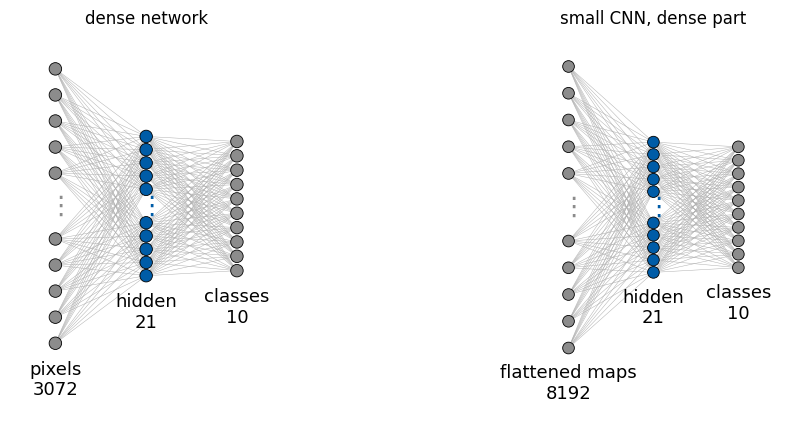

In [16]:
def dense_sizes(*layers):
    # layer sizes read from the nnx.Linear layers of a model: input of the first, then the output of each
    return [layers[0].in_features] + [l.out_features for l in layers]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, m, labels, title in [(axes[0], dense, ["pixels", "hidden", "classes"], "dense network"),
                             (axes[1], small, ["flattened maps", "hidden", "classes"], "small CNN, dense part")]:
    sizes = dense_sizes(m.fc1, m.fc2)
    draw_network(sizes, labels=labels, ax=ax); ax.set_title(title)
    n_drawn = sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))     # weights and biases of the drawn edges
    assert n_drawn == count_params(m.fc1) + count_params(m.fc2)
    print(f"{title}: layers {sizes}, {n_drawn} parameters in the drawn layers, {count_params(m)} in the model")
plt.show()


The library way in Flax is `nnx.tabulate(model, x)`. It calls the model on the example input `x` and returns a table with one row per submodule: its path, its type, the shapes of its inputs and outputs and its parameters (`Param`), with the totals in the first and last rows. Batch-normalisation statistics (`BatchStat`) and the random-number states of dropout (`RngState`) get columns of their own. The model is not changed. We pass zeros in the JAX layout $(N,H,W,C)$ and print the table as plain text (`console_kwargs` sets its width). In Jupyter or Google Colab, `nnx.display(model)` shows the same tree of modules and parameters interactively, through the package `treescope`. A drawing of the computation graph such as PyTorch's `torchview` has no direct counterpart for Flax; the table, which checks shapes and counts parameters, together with our drawing of the dense layers covers what is needed here. The totals reproduce the asserted counts, $64\,753$ and $173\,169$.

In [17]:
for name, m in [("dense network", dense), ("small CNN", small)]:
    print(name)
    print(nnx.tabulate(m, jnp.zeros((1, 32, 32, 3)), console_kwargs=dict(width=110, color_system=None)))


dense network


DenseNet Summary                                  
┏━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path ┃ type     ┃ inputs             ┃ outputs       ┃ Param                    ┃
┡━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      │ DenseNet │ float32[1,32,32,3] │ float32[1,10] │ 64,753 (259.0 KB)        │
├──────┼──────────┼────────────────────┼───────────────┼──────────────────────────┤
│ fc1  │ Linear   │ float32[1,3072]    │ float32[1,21] │ bias: float32[21]        │
│      │          │                    │               │ kernel: float32[3072,21] │
│      │          │                    │               │                          │
│      │          │                    │               │ 64,533 (258.1 KB)        │
├──────┼──────────┼────────────────────┼───────────────┼──────────────────────────┤
│ fc2  │ Linear   │ float32[1,21]      │ float32[1,10] │ bias: float32[10]        │
│      │          │                    │               │ kernel: float32[21,10]   │
│      │          │                    │               │                          │
│      │          │                    │               │ 220 (880 B)              │
├──────┼──────────┼────────────────────┼───────────────┼──────────────────────────┤
│      │          │                    │         Total │ 64,753 (259.0 KB)        │
└──────┴──────────┴────────────────────┴───────────────┴──────────────────────────┘
                                                                                   
                        Total Parameters: 64,753 (259.0 KB)


small CNN


SmallCNN Summary                                      
┏━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path  ┃ type     ┃ inputs             ┃ outputs             ┃ Param                     ┃
┡━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       │ SmallCNN │ float32[1,32,32,3] │ float32[1,10]       │ 173,169 (692.7 KB)        │
├───────┼──────────┼────────────────────┼─────────────────────┼───────────────────────────┤
│ conv1 │ Conv     │ float32[1,32,32,3] │ float32[1,32,32,32] │ bias: float32[32]         │
│       │          │                    │                     │ kernel: float32[3,3,3,32] │
│       │          │                    │                     │                           │
│       │          │                    │                     │ 896 (3.6 KB)              │
├───────┼──────────┼────────────────────┼─────────────────────┼───────────────────────────┤
│ fc1   │ Linear   │ float32[1,8192]    │ float32[1,21]       │ bias: float32[21]         │
│       │          │                    │                     │ kernel: float32[8192,21]  │
│       │          │                    │                     │                           │
│       │          │                    │                     │ 172,053 (688.2 KB)        │
├───────┼──────────┼────────────────────┼─────────────────────┼───────────────────────────┤
│ fc2   │ Linear   │ float32[1,21]      │ float32[1,10]       │ bias: float32[10]         │
│       │          │                    │                     │ kernel: float32[21,10]    │
│       │          │                    │                     │                           │
│       │          │                    │                     │ 220 (880 B)               │
├───────┼──────────┼────────────────────┼─────────────────────┼───────────────────────────┤
│       │          │                    │               Total │ 173,169 (692.7 KB)        │
└───────┴──────────┴────────────────────┴─────────────────────┴───────────────────────────┘
                                                                                           
                           Total Parameters: 173,169 (692.7 KB)

In [18]:
hist = {}
hist["dense"] = train(dense, Xc_tr, yc_tr, Xc_te, yc_te, EPOCHS_SHORT, name="dense")
hist["small CNN"] = train(small, Xc_tr, yc_tr, Xc_te, yc_te, EPOCHS_SHORT, name="small CNN")
for n, m in [("dense", dense), ("small CNN", small)]: print("saved", save(m, n.replace(" ", "_")))

dense epoch 1/3: train acc 0.395, test acc 0.382, test loss 1.797  (5 s)


dense epoch 2/3: train acc 0.409, test acc 0.391, test loss 1.749  (7 s)


dense epoch 3/3: train acc 0.410, test acc 0.394, test loss 1.735  (9 s)


small CNN epoch 1/3: train acc 0.486, test acc 0.474, test loss 1.649  (50 s)


small CNN epoch 2/3: train acc 0.555, test acc 0.531, test loss 1.393  (82 s)


small CNN epoch 3/3: train acc 0.609, test acc 0.576, test loss 1.255  (113 s)
saved results/Lab_013b_dense.msgpack
saved results/Lab_013b_small_CNN.msgpack


In [19]:
SLIDE = {"dense": (46, 41), "small CNN": (82, 60), "larger CNN": (100, 71), "regularised CNN": (90, 82)}   # Keras, long training

def report(names, models):
    print(f"{'model':16s} {'params':>10s} {'images':>6s} {'epochs':>6s} | {'train acc':>9s} {'test acc':>8s} | slides (Keras): train / test")
    for n in names:
        h = hist[n]
        print(f"{n:16s} {count_params(models[n]):10d} {h['n_train']:6d} {len(h['test_acc']):6d} | {100 * h['train_acc'][-1]:8.1f}% {100 * h['test_acc'][-1]:7.1f}% |"
              f" {SLIDE[n][0]}% / {SLIDE[n][1]}%")
models = {"dense": dense, "small CNN": small}
report(["dense", "small CNN"], models)

model                params images epochs | train acc test acc | slides (Keras): train / test
dense                 64753  50000      3 |     41.0%    39.4% | 46% / 41%
small CNN            173169  50000      3 |     60.9%    57.6% | 82% / 60%


After 3 epochs the dense network reaches 41.0% training and 39.4% test accuracy, close to the 46% / 41% of the slides: it is already near its limit. The small CNN, with the same budget, reaches 60.9% / 57.6%, close to the slide's test accuracy of 60%; its training accuracy is still far below the slide's 82% because it has not yet had time to overfit. The CNN has more parameters (173 169 against 64 753), but almost all of them sit in the dense layer after the flattening ($172\,053$, the middle term of equation (14)); the convolution itself has 896. The gain comes from the structure: 32 small kernels shared over all positions, instead of one weight per pixel. The confusion matrices (Section 4) show where both still fail: the dense network sends 272 of the 1000 aeroplanes to "ship" (blue background in both).

## 3. A CNN on MNIST

Architecture (rectified linear unit, ReLU, $\max(0,z)$, as activation):

| layer | output shape | parameters |
|---|---|---|
| input | $(N,28,28,1)$ | |
| `conv1`: Conv $1\to16$, $3\times3$, padding "SAME", ReLU | $(N,28,28,16)$ | $160$ |
| max pooling $2\times2$ | $(N,14,14,16)$ | 0 |
| `conv2`: Conv $16\to32$, $3\times3$, padding "SAME", ReLU | $(N,14,14,32)$ | $4640$ |
| max pooling $2\times2$ | $(N,7,7,32)$ | 0 |
| `fc`: flatten, dense $1568\to10$ | $(N,10)$ | $15\,690$ |

The parameter counts of the table are
$$1\cdot9\cdot16+16=160,\qquad 16\cdot9\cdot32+32=4640,\qquad 1568\cdot10+10=15\,690, \tag{15}$$
in total $20\,490$ parameters. Before training we keep a copy of the initial parameters, to compare kernels at initialisation and after training in Section 5.

In [20]:
class MnistCNN(nnx.Module):
    def __init__(self, rngs):
        self.conv1 = nnx.Conv(1, 16, (3, 3), padding="SAME", rngs=rngs)
        self.conv2 = nnx.Conv(16, 32, (3, 3), padding="SAME", rngs=rngs)
        self.fc = nnx.Linear(32 * 7 * 7, 10, rngs=rngs)
    def __call__(self, x):
        h = nnx.max_pool(nnx.relu(self.conv1(x)), (2, 2), strides=(2, 2))
        h = nnx.max_pool(nnx.relu(self.conv2(h)), (2, 2), strides=(2, 2))
        return self.fc(h.reshape(h.shape[0], -1))

mnist_cnn = MnistCNN(nnx.Rngs(0))
mnist_init = weights_dict(mnist_cnn)                     # parameters at initialisation (NumPy copies)
assert count_params(mnist_cnn) == 20490
hist["MNIST CNN"] = train(mnist_cnn, Xm_tr4, ym_tr, Xm_te4, ym_te, EPOCHS_MNIST, name="MNIST CNN")
print("saved", save(mnist_cnn, "mnist_cnn"))

MNIST CNN epoch 1/2: train acc 0.976, test acc 0.978, test loss 0.073  (22 s)


MNIST CNN epoch 2/2: train acc 0.979, test acc 0.982, test loss 0.059  (42 s)
saved results/Lab_013b_mnist_cnn.msgpack


`nnx.tabulate` rebuilds the table above from the model itself. The final dense layer, $1568\to10$, holds $15\,690$ of the $20\,490$ parameters.

In [21]:
print(nnx.tabulate(mnist_cnn, jnp.zeros((1, 28, 28, 1)), console_kwargs=dict(width=110, color_system=None)))


MnistCNN Summary                                       
┏━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path  ┃ type     ┃ inputs              ┃ outputs             ┃ Param                      ┃
┡━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       │ MnistCNN │ float32[1,28,28,1]  │ float32[1,10]       │ 20,490 (82.0 KB)           │
├───────┼──────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ conv1 │ Conv     │ float32[1,28,28,1]  │ float32[1,28,28,16] │ bias: float32[16]          │
│       │          │                     │                     │ kernel: float32[3,3,1,16]  │
│       │          │                     │                     │                            │
│       │          │                     │                     │ 160 (640 B)                │
├───────┼──────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ conv2 │ Conv     │ float32[1,14,14,16] │ float32[1,14,14,32] │ bias: float32[32]          │
│       │          │                     │                     │ kernel: float32[3,3,16,32] │
│       │          │                     │                     │                            │
│       │          │                     │                     │ 4,640 (18.6 KB)            │
├───────┼──────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│ fc    │ Linear   │ float32[1,1568]     │ float32[1,10]       │ bias: float32[10]          │
│       │          │                     │                     │ kernel: float32[1568,10]   │
│       │          │                     │                     │                            │
│       │          │                     │                     │ 15,690 (62.8 KB)           │
├───────┼──────────┼─────────────────────┼─────────────────────┼────────────────────────────┤
│       │          │                     │               Total │ 20,490 (82.0 KB)           │
└───────┴──────────┴─────────────────────┴─────────────────────┴────────────────────────────┘
                                                                                             
                             Total Parameters: 20,490 (82.0 KB)

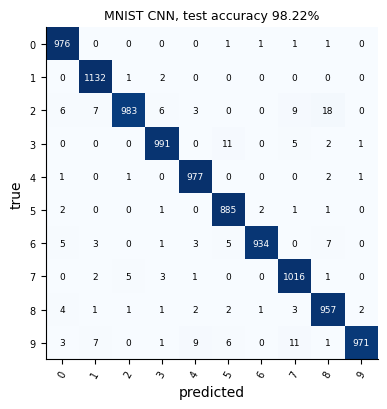

test errors: 178 of 10000; most frequent confusion: 2 predicted as 8 (18 times)


In [22]:
pred_m = predict(mnist_cnn, Xm_te4).argmax(1)
cm_m = confusion_matrix(ym_te, pred_m)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
plot_confusion(ax, cm_m, [str(d) for d in range(10)], f"MNIST CNN, test accuracy {100 * (pred_m == ym_te).mean():.2f}%")
plt.tight_layout(); plt.show()
off = cm_m - np.diag(np.diag(cm_m)); a, b = np.unravel_index(off.argmax(), off.shape)
print(f"test errors: {off.sum()} of 10000; most frequent confusion: {a} predicted as {b} ({off[a, b]} times)")

With 20 490 parameters and 2 epochs the CNN reaches 98.22% test accuracy on MNIST (178 errors in 10 000), against about 98% training accuracy: no overfitting. The errors are spread thinly; the most frequent single confusion is a 2 read as an 8 (18 times).

## 4. Capacity and regularisation of CNNs on CIFAR-10

### Larger CNN and regularised CNN

Both models share one class, `CifarCNN`, with a convolutional **body** and a dense **head** (the names matter later: Section 10 reuses the body):

| layer (body) | output shape |
|---|---|
| `conv1` $3\to32$, $3\times3$, "SAME", [`bn1`], ReLU `act1`, max pool | $(N,16,16,32)$ |
| `conv2` $32\to64$, [`bn2`], ReLU `act2`, max pool, [`drop2`] | $(N,8,8,64)$ |
| `conv3` $64\to128$, [`bn3`], ReLU `act3`, max pool, [`drop3`] | $(N,4,4,128)$ |
| **head**: flatten $2048$, [`drop4`], dense 512 `fc1`, ReLU, dense 10 `fc2` | $(N,10)$ |

To see overfitting within a few minutes of CPU time, these two models are trained on the first `N_SUB` = 10 000 training images (about 1000 per class) for `EPOCHS_LARGE` = 12 epochs; the test set is the full set of 10 000 test images. The training accuracy is measured on the 10 000 training images used. With fewer training images a network memorises them sooner, so the gap between training and test accuracy opens after a few epochs instead of a few tens of epochs on the full set.

Layers in brackets exist only in the regularised model (in the larger model the attribute is `None` and the step is skipped). The regularised model combines the four techniques of the lecture. **Batch normalisation** (`bn`) normalises each channel over the mini-batch and rescales it with trainable $\gamma,\beta$,
$$\hat x = \frac{x-\mu_B}{\sqrt{\sigma_B^2+\epsilon}},\qquad x\leftarrow\gamma\hat x+\beta; \tag{16}$$
at test time running averages of $\mu_B,\sigma_B^2$ are used (we set `momentum=0.9`, the PyTorch default). **Dropout** (`drop`), with rates 0.2, 0.3 and 0.4, sets each unit to zero with that probability during training. **L2 weight decay** uses $\text{wd}=5\cdot10^{-4}$. Finally, **data augmentation** flips each training image left–right with probability 1/2 and shifts it by up to 4 pixels in each direction (zero padding, then a random $32\times32$ crop), inside the compiled training step.

The body has a method `activations(x)` that returns every intermediate result in a dictionary; `__call__` uses it and returns only the last entry. Section 7 explains why.

In [23]:
class CifarBody(nnx.Module):
    def __init__(self, regularise, rngs):
        bn = (lambda c: nnx.BatchNorm(c, momentum=0.9, rngs=rngs)) if regularise else (lambda c: None)
        drop = (lambda p: nnx.Dropout(p, rngs=rngs)) if regularise else (lambda p: None)
        self.conv1, self.bn1 = nnx.Conv(3, 32, (3, 3), padding="SAME", rngs=rngs), bn(32)
        self.conv2, self.bn2, self.drop2 = nnx.Conv(32, 64, (3, 3), padding="SAME", rngs=rngs), bn(64), drop(0.2)
        self.conv3, self.bn3, self.drop3 = nnx.Conv(64, 128, (3, 3), padding="SAME", rngs=rngs), bn(128), drop(0.3)
    def activations(self, x):
        a = {}
        h = x
        for l, (conv, bn, drop) in enumerate([(self.conv1, self.bn1, None), (self.conv2, self.bn2, self.drop2),
                                              (self.conv3, self.bn3, self.drop3)], start=1):
            h = conv(h)
            if bn is not None: h = bn(h)
            h = a[f"act{l}"] = nnx.relu(h)
            h = a[f"pool{l}"] = nnx.max_pool(h, (2, 2), strides=(2, 2))
            if drop is not None: h = drop(h)
        a["out"] = h                                            # (N, 4, 4, 128)
        return a
    def __call__(self, x):
        return self.activations(x)["out"]

class CifarHead(nnx.Module):
    def __init__(self, regularise, rngs):
        self.drop4 = nnx.Dropout(0.4, rngs=rngs) if regularise else None
        self.fc1, self.fc2 = nnx.Linear(2048, 512, rngs=rngs), nnx.Linear(512, 10, rngs=rngs)
    def __call__(self, h):
        h = h.reshape(h.shape[0], -1)
        if self.drop4 is not None: h = self.drop4(h)
        return self.fc2(nnx.relu(self.fc1(h)))

class CifarCNN(nnx.Module):
    def __init__(self, regularise, rngs):
        self.body, self.head = CifarBody(regularise, rngs), CifarHead(regularise, rngs)
    def __call__(self, x):
        return self.head(self.body(x))

larger = CifarCNN(False, nnx.Rngs(params=0, dropout=1))
regular = CifarCNN(True, nnx.Rngs(params=0, dropout=1))
regular_init = weights_dict(regular)
xa = augment(jnp.asarray(Xc_tr[:4]), jax.random.key(0)); assert xa.shape == (4, 32, 32, 3)
print("parameters: larger", count_params(larger), " regularised", count_params(regular),
      "(the difference is the batch-norm scales and shifts)")
print("body output:", larger.body(jnp.asarray(Xc_tr[:2])).shape)

parameters: larger 1147466  regularised 1147914 (the difference is the batch-norm scales and shifts)


body output: (2, 4, 4, 128)


In the larger model the batch-normalisation and dropout attributes are `None` and do not appear in its table. The two models differ by the scales and shifts of batch normalisation, 
$$2\cdot(32+64+128)=448 \tag{17}$$
parameters; the running means and variances are listed under `BatchStat` and are not parameters. The dense head, drawn below, has 
$$2048\cdot512+512=1\,049\,088 \tag{18}$$
parameters in its first layer alone, over 90% of the model.

In [24]:
for name, m in [("larger CNN", larger), ("regularised CNN", regular)]:
    print(name)
    print(nnx.tabulate(m, jnp.zeros((1, 32, 32, 3)), console_kwargs=dict(width=110, color_system=None)))


larger CNN


CifarCNN Summary                                               
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path             ┃ type      ┃ inputs              ┃ outputs                   ┃ Param                     ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│                  │ CifarCNN  │ float32[1,32,32,3]  │ float32[1,10]             │ 1,147,466 (4.6 MB)        │
├──────────────────┼───────────┼─────────────────────┼───────────────────────────┼───────────────────────────┤
│ body/activations │ CifarBody │ float32[1,32,32,3]  │ act1: float32[1,32,32,32] │ 93,248 (373.0 KB)         │
│                  │           │                     │ act2: float32[1,16,16,64] │                           │
│                  │           │                     │ act3: float32[1,8,8,128]  │                           │
│                  │           │                     │ out: float32[1,4,4,128]   │                           │
│                  │           │                     │ pool1:                    │                           │
│                  │           │                     │ float32[1,16,16,32]       │                           │
│                  │           │                     │ pool2: float32[1,8,8,64]  │                           │
│                  │           │                     │ pool3: float32[1,4,4,128] │                           │
├──────────────────┼───────────┼─────────────────────┼───────────────────────────┼───────────────────────────┤
│ body/conv1       │ Conv      │ float32[1,32,32,3]  │ float32[1,32,32,32]       │ bias: float32[32]         │
│                  │           │                     │                           │ kernel: float32[3,3,3,32] │
│                  │           │                     │                           │                           │
│                  │           │                     │                           │ 896 (3.6 KB)              │
├──────────────────┼───────────┼─────────────────────┼───────────────────────────┼───────────────────────────┤
│ body/conv2       │ Conv      │ float32[1,16,16,32] │ float32[1,16,16,64]       │ bias: float32[64]         │
│                  │           │                     │                           │ kernel:                   │
│                  │           │                     │                           │ float32[3,3,32,64]        │
│                  │           │                     │                           │                           │
│                  │           │                     │                           │ 18,496 (74.0 KB)          │
├──────────────────┼───────────┼─────────────────────┼───────────────────────────┼───────────────────────────┤
│ body/conv3       │ Conv      │ float32[1,8,8,64]   │ float32[1,8,8,128]        │ bias: float32[128]        │
│                  │           │                     │                           │ kernel:                   │
│                  │           │                     │                           │ float32[3,3,64,128]       │
│                  │           │                     │                           │                           │
│                  │           │                     │                           │ 73,856 (295.4 KB)         │
├──────────────────┼───────────┼─────────────────────┼───────────────────────────┼───────────────────────────┤
│ head             │ CifarHead │ float32[1,4,4,128]  │ float32[1,10]             │ 1,054,218 (4.2 MB)        │
├──────────────────┼───────────┼─────────────────────┼───────────────────────────┼───────────────────────────┤
│ head/fc1         │ Linear    │ float32[1,2048]     │ float32[1,512]            │ bias: float32[512]        │
│                  │           │                     │                           │ kernel: float32[2048,512] │
│                  │           │                   


regularised CNN


CifarCNN Summary                                               
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ path           ┃ type      ┃ inputs         ┃ outputs        ┃ BatchStat      ┃ Param           ┃ RngState ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│                │ CifarCNN  │ float32[1,32,… │ float32[1,10]  │ 448 (1.8 KB)   │ 1,147,914 (4.6  │ 6 (36 B) │
│                │           │                │                │                │ MB)             │          │
├────────────────┼───────────┼────────────────┼────────────────┼────────────────┼─────────────────┼──────────┤
│ body/activati… │ CifarBody │ float32[1,32,… │ act1:          │ 448 (1.8 KB)   │ 93,696 (374.8   │ 4 (24 B) │
│                │           │                │ float32[1,32,… │                │ KB)             │          │
│                │           │                │ act2:          │                │                 │          │
│                │           │                │ float32[1,16,… │                │                 │          │
│                │           │                │ act3:          │                │                 │          │
│                │           │                │ float32[1,8,8… │                │                 │          │
│                │           │                │ out:           │                │                 │          │
│                │           │                │ float32[1,4,4… │                │                 │          │
│                │           │                │ pool1:         │                │                 │          │
│                │           │                │ float32[1,16,… │                │                 │          │
│                │           │                │ pool2:         │                │                 │          │
│                │           │                │ float32[1,8,8… │                │                 │          │
│                │           │                │ pool3:         │                │                 │          │
│                │           │                │ float32[1,4,4… │                │                 │          │
├────────────────┼───────────┼────────────────┼────────────────┼────────────────┼─────────────────┼──────────┤
│ body/conv1     │ Conv      │ float32[1,32,… │ float32[1,32,… │                │ bias:           │          │
│                │           │                │                │                │ float32[32]     │          │
│                │           │                │                │                │ kernel:         │          │
│                │           │                │                │                │ float32[3,3,3,… │          │
│                │           │                │                │                │                 │          │
│                │           │                │                │                │ 896 (3.6 KB)    │          │
├────────────────┼───────────┼────────────────┼────────────────┼────────────────┼─────────────────┼──────────┤
│ body/bn1       │ BatchNorm │ float32[1,32,… │ float32[1,32,… │ mean:          │ bias:           │          │
│                │           │                │                │ float32[32]    │ float32[32]     │          │
│                │           │                │                │ var:           │ scale:          │          │
│                │           │                │                │ float32[32]    │ float32[32]     │          │
│                │           │                │                │                │                 │          │
│                │           │                │                │ 64 (256 B)     │ 64 (256 B)      │          │
├────────────────┼───────────┼────────────────┼────────────────┼────────────────┼─────────────────┼──────────┤
│ body/conv2     │ Conv      │ float32[1,16,… │ flo

head: layers [2048, 512, 10], 1054218 of the 1147466 parameters of the larger CNN


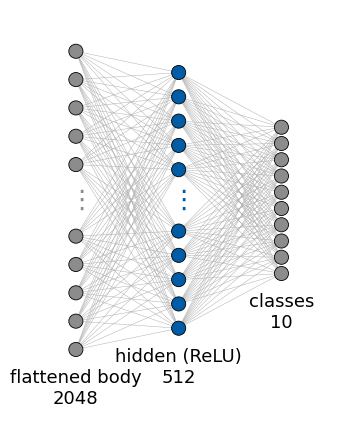

In [25]:
sizes = dense_sizes(larger.head.fc1, larger.head.fc2)
draw_network(sizes, labels=["flattened body", "hidden (ReLU)", "classes"])
n_drawn = sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))
assert n_drawn == count_params(larger.head)
print(f"head: layers {sizes}, {n_drawn} of the {count_params(larger)} parameters of the larger CNN")
plt.show()


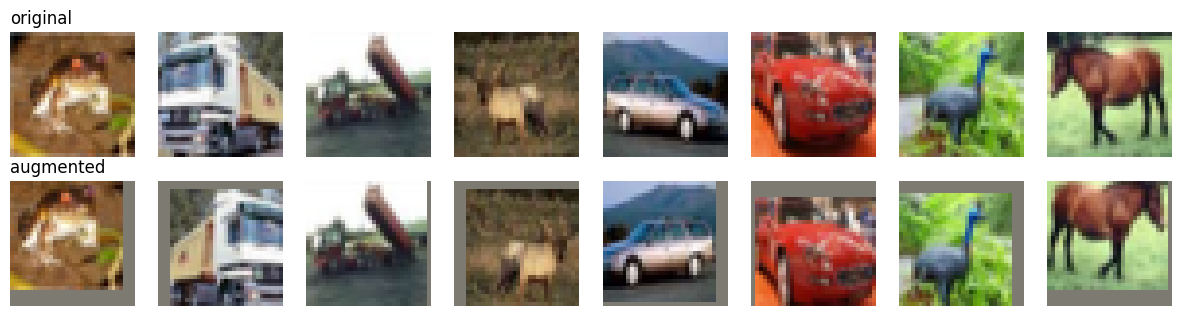

In [26]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
x8 = Xc_tr[:8]; xa8 = np.asarray(augment(jnp.asarray(x8), jax.random.key(1)))
to_img = lambda a: np.clip(a * CIFAR_STD + CIFAR_MEAN, 0, 1)        # undo the standardisation
for k in range(8):
    axes[0, k].imshow(to_img(x8[k])); axes[1, k].imshow(to_img(xa8[k]))
for a in axes.ravel(): a.axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("augmented", loc="left"); plt.tight_layout(); plt.show()

The augmented copies are mirrored or shifted versions of the same objects (the black bands are the zero padding, which after standardisation is the mean colour; it appears dark here because the plot undoes the standardisation). Each epoch the network sees a new random variant of every training image.

In [27]:
hist["larger CNN"] = train(larger, Xc_tr[:N_SUB], yc_tr[:N_SUB], Xc_te, yc_te, EPOCHS_LARGE, name="larger CNN")
print("saved", save(larger, "larger_cnn"))

larger CNN epoch 1/12: train acc 0.453, test acc 0.426, test loss 1.578  (15 s)


larger CNN epoch 2/12: train acc 0.520, test acc 0.474, test loss 1.449  (28 s)


larger CNN epoch 3/12: train acc 0.589, test acc 0.528, test loss 1.305  (41 s)


larger CNN epoch 4/12: train acc 0.682, test acc 0.566, test loss 1.228  (56 s)


larger CNN epoch 5/12: train acc 0.720, test acc 0.578, test loss 1.210  (71 s)


...

larger CNN epoch 8/12: train acc 0.915, test acc 0.617, test loss 1.249  (112 s)


larger CNN epoch 9/12: train acc 0.933, test acc 0.614, test loss 1.350  (126 s)


larger CNN epoch 10/12: train acc 0.936, test acc 0.610, test loss 1.493  (141 s)


larger CNN epoch 11/12: train acc 0.982, test acc 0.616, test loss 1.674  (156 s)


larger CNN epoch 12/12: train acc 0.984, test acc 0.614, test loss 1.819  (169 s)
saved results/Lab_013b_larger_cnn.msgpack


In [28]:
hist["regularised CNN"] = train(regular, Xc_tr[:N_SUB], yc_tr[:N_SUB], Xc_te, yc_te, EPOCHS_LARGE, weight_decay=5e-4,
                                use_augment=True, name="regularised CNN")
print("saved", save(regular, "regularised_cnn"))

regularised CNN epoch 1/12: train acc 0.392, test acc 0.387, test loss 1.678  (21 s)


regularised CNN epoch 2/12: train acc 0.472, test acc 0.464, test loss 1.480  (36 s)


regularised CNN epoch 3/12: train acc 0.481, test acc 0.469, test loss 1.469  (50 s)


regularised CNN epoch 4/12: train acc 0.508, test acc 0.503, test loss 1.374  (64 s)


regularised CNN epoch 5/12: train acc 0.525, test acc 0.514, test loss 1.339  (78 s)


...

regularised CNN epoch 8/12: train acc 0.601, test acc 0.588, test loss 1.164  (125 s)


regularised CNN epoch 9/12: train acc 0.641, test acc 0.616, test loss 1.086  (142 s)


regularised CNN epoch 10/12: train acc 0.641, test acc 0.618, test loss 1.096  (160 s)


regularised CNN epoch 11/12: train acc 0.651, test acc 0.623, test loss 1.061  (180 s)


regularised CNN epoch 12/12: train acc 0.678, test acc 0.647, test loss 0.994  (201 s)
saved results/Lab_013b_regularised_cnn.msgpack


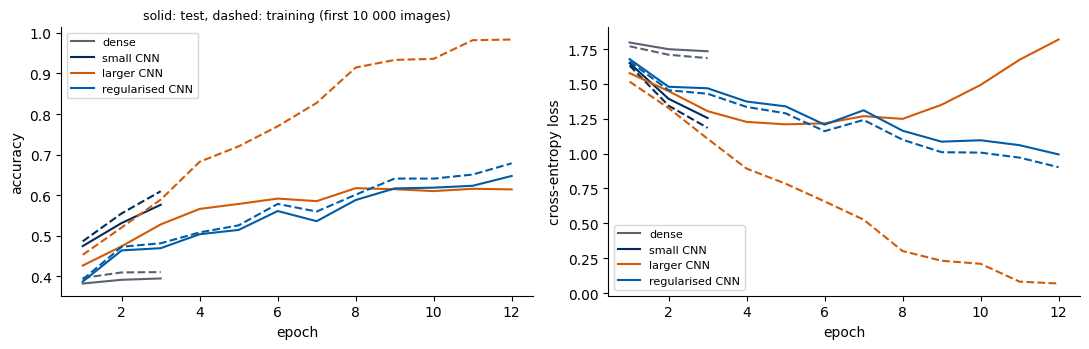

model                params images epochs | train acc test acc | slides (Keras): train / test
dense                 64753  50000      3 |     41.0%    39.4% | 46% / 41%
small CNN            173169  50000      3 |     60.9%    57.6% | 82% / 60%
larger CNN          1147466  10000     12 |     98.4%    61.4% | 100% / 71%
regularised CNN     1147914  10000     12 |     67.8%    64.7% | 90% / 82%


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cols = {"dense": UJGray, "small CNN": UJNavy, "larger CNN": DSOrange, "regularised CNN": UJBlue}
for n, c in cols.items():
    h = hist[n]; ep = np.arange(1, len(h["test_acc"]) + 1)
    axes[0].plot(ep, h["train_acc"], "--", color=c); axes[0].plot(ep, h["test_acc"], "-", color=c, label=n)
    axes[1].plot(ep, h["train_loss"], "--", color=c); axes[1].plot(ep, h["test_loss"], "-", color=c, label=n)
axes[0].set_ylabel("accuracy"); axes[1].set_ylabel("cross-entropy loss")
for a in axes: a.set_xlabel("epoch"); a.legend(fontsize=8); a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_title("solid: test, dashed: training (first 10 000 images)", fontsize=9)
plt.tight_layout(); plt.show()
models.update({"larger CNN": larger, "regularised CNN": regular})
report(list(cols), models)

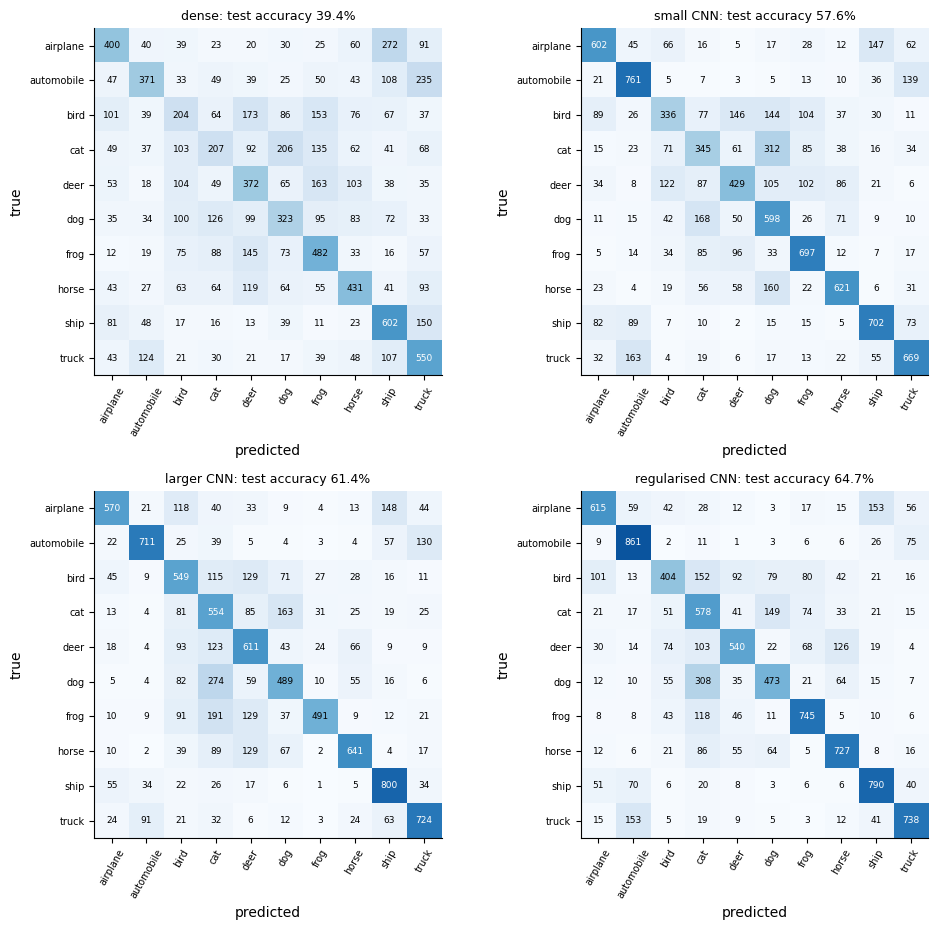

dense            most frequent confusion: airplane -> ship (272 of 1000)
small CNN        most frequent confusion: cat -> dog (312 of 1000)
larger CNN       most frequent confusion: dog -> cat (274 of 1000)
regularised CNN  most frequent confusion: dog -> cat (308 of 1000)


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9.4))
cm_cifar = {}
for a, n in zip(axes.ravel(), cols):
    pred = predict(models[n], Xc_te).argmax(1)
    cm_cifar[n] = confusion_matrix(yc_te, pred)
    plot_confusion(a, cm_cifar[n], CLASSES, f"{n}: test accuracy {100 * (pred == yc_te).mean():.1f}%")
plt.tight_layout(); plt.show()
for n in cols:
    off = cm_cifar[n] - np.diag(np.diag(cm_cifar[n])); a, b = np.unravel_index(off.argmax(), off.shape)
    print(f"{n:16s} most frequent confusion: {CLASSES[a]} -> {CLASSES[b]} ({off[a, b]} of 1000)")

Measured on 10 000 training images and 12 epochs, the larger CNN reaches 98.4% training but only 61.4% test accuracy (slides: 100% / 71% on all 50 000 images with long training). Its test loss is smallest around epochs 5–6 (1.21) and then rises to 1.82 while the training loss keeps falling to 0.07: the network memorises the training images, the definition of overfitting. The regularised CNN, with batch normalisation, dropout, weight decay and augmentation, ends at 67.8% / 64.7% (slides: 90% / 82%): the training and test curves stay together, the test loss is still falling at epoch 12 (0.99), and the test accuracy is already 3.3 points higher than for the larger CNN. Regularisation does not make training faster; it makes the measured training performance a reliable estimate of the test performance and leaves room for further training, which on the slides gave 82%. In all four confusion matrices the largest confusions are between animals of similar shape and colour, most of all cat and dog (larger CNN: 274 dogs predicted as cat).

## 5. Kernels of a layer

In Flax a layer is an attribute of its parent module, so its kernel is reached by the attribute path, e.g. `regular.body.conv1.kernel`; `kernel[...]` returns the array. `nnx.state(model, nnx.Param)` collects all parameters in a nested dictionary keyed by the same names. The kernel of `nnx.Conv` has shape $(k_h, k_w, C_{\text{in}}, C_{\text{out}})$. Axes 0 and 1 are the kernel rows $m$ and columns $n$; axis 2 is the input channel $c$, because the kernel has one $k_h\times k_w$ slice per input channel; axis 3 is the output channel $o$, with one kernel per feature map produced. PyTorch stores the same numbers as $(C_{\text{out}}, C_{\text{in}}, k_h, k_w)$; `jnp.transpose(kernel, (3, 2, 0, 1))` converts one into the other.

In [31]:
flat, _ = jax.tree_util.tree_flatten_with_path(nnx.to_pure_dict(nnx.state(mnist_cnn, nnx.Param)))
for path, leaf in flat:
    name = ".".join(str(p.key) for p in path)
    print(f"{name:14s} {str(leaf.shape):18s} {leaf.size:6d} parameters")
W1_mnist = np.asarray(mnist_cnn.conv1.kernel[...])                      # (3, 3, 1, 16)
W1_cifar = np.asarray(regular.body.conv1.kernel[...])                   # (3, 3, 3, 32)
assert np.array_equal(W1_cifar, nnx.state(regular, nnx.Param)["body"]["conv1"]["kernel"][...])
W1_cifar_torch_order = np.transpose(W1_cifar, (3, 2, 0, 1))             # (32, 3, 3, 3) = (out, in, kh, kw)
print("MNIST conv1:", W1_mnist.shape, " CIFAR body.conv1:", W1_cifar.shape, "-> PyTorch order", W1_cifar_torch_order.shape)

conv1.bias     (16,)                  16 parameters
conv1.kernel   (3, 3, 1, 16)         144 parameters
conv2.bias     (32,)                  32 parameters
conv2.kernel   (3, 3, 16, 32)       4608 parameters
fc.bias        (10,)                  10 parameters
fc.kernel      (1568, 10)          15680 parameters
MNIST conv1: (3, 3, 1, 16)  CIFAR body.conv1: (3, 3, 3, 32) -> PyTorch order (32, 3, 3, 3)


To display a kernel as an image, each kernel is rescaled separately to $[0,1]$: $(W-\min W)/(\max W-\min W)$. The absolute scale is lost; only the pattern is shown. MNIST kernels have one input channel and are shown in grey; CIFAR-10 kernels have three input channels, which we display as the red, green and blue of a $3\times3$ colour image (axes reordered to $(C_{\text{out}}, k_h, k_w, C_{\text{in}})$).

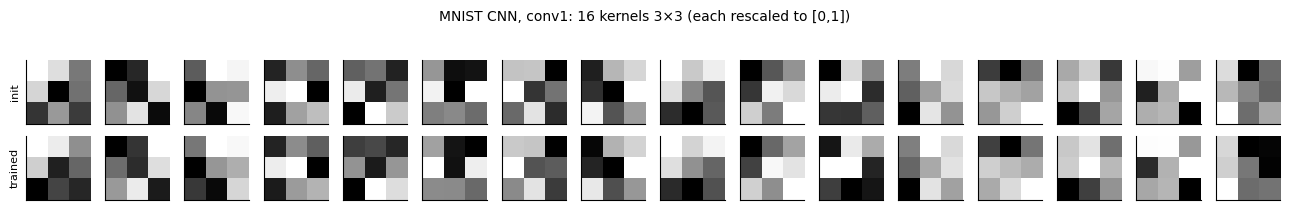

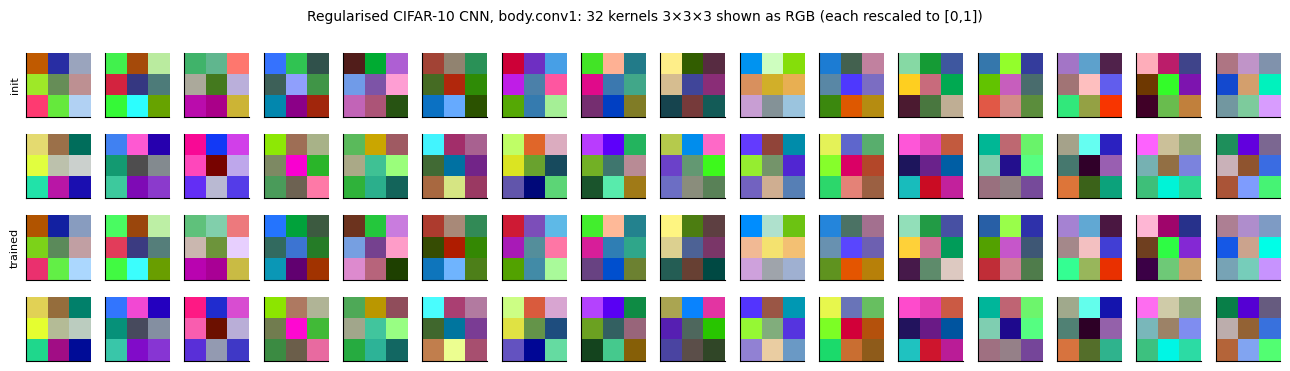

MNIST conv1: relative change ||W_trained - W_init|| / ||W_init|| = 0.34
CIFAR conv1: relative change ||W_trained - W_init|| / ||W_init|| = 0.26


In [32]:
def normalise01(w):
    # rescale each kernel (first axis) separately to [0, 1]
    w = np.asarray(w, dtype=np.float64)
    lo = w.reshape(len(w), -1).min(1).reshape(-1, *[1] * (w.ndim - 1)); hi = w.reshape(len(w), -1).max(1).reshape(-1, *[1] * (w.ndim - 1))
    return (w - lo) / (hi - lo + 1e-12)

def show_kernels(axes, K, cmap=None):
    # K: (n, kh, kw) greyscale or (n, kh, kw, 3) colour
    for a, k in zip(axes, normalise01(K)):
        a.imshow(k, cmap=cmap, vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])

W1m_init = mnist_init["conv1"]["kernel"][:, :, 0, :].transpose(2, 0, 1); W1m = W1_mnist[:, :, 0, :].transpose(2, 0, 1)   # (16, 3, 3)
W1c_init = regular_init["body"]["conv1"]["kernel"].transpose(3, 0, 1, 2)                                            # (32, 3, 3, 3)
W1c = W1_cifar.transpose(3, 0, 1, 2)                                                                                 # (out, kh, kw, in)
fig, axes = plt.subplots(2, 16, figsize=(13, 2.2))
show_kernels(axes[0], W1m_init, "gray"); show_kernels(axes[1], W1m, "gray")
axes[0, 0].set_ylabel("init", fontsize=8); axes[1, 0].set_ylabel("trained", fontsize=8)
fig.suptitle("MNIST CNN, conv1: 16 kernels 3×3 (each rescaled to [0,1])", fontsize=10); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(4, 16, figsize=(13, 3.8))
show_kernels(axes[:2].ravel(), W1c_init); show_kernels(axes[2:].ravel(), W1c)
axes[0, 0].set_ylabel("init", fontsize=8); axes[2, 0].set_ylabel("trained", fontsize=8)
fig.suptitle("Regularised CIFAR-10 CNN, body.conv1: 32 kernels 3×3×3 shown as RGB (each rescaled to [0,1])", fontsize=10)
plt.tight_layout(); plt.show()
for n, a, b in [("MNIST", W1m_init, W1m), ("CIFAR", W1c_init, W1c)]:
    rel = np.linalg.norm(b - a) / np.linalg.norm(a)
    print(f"{n} conv1: relative change ||W_trained - W_init|| / ||W_init|| = {rel:.2f}")

The relative change of the first-layer kernels during training is 0.34 for the MNIST CNN and 0.26 for the CIFAR-10 CNN, so in both cases the trained kernels are still recognisably their random initial patterns, modified rather than replaced (compare the rows "init" and "trained"). A $3\times3$ kernel has only 9 (or 27) numbers: pictures of such kernels are hard to read by eye, and the clean oriented edge detectors seen in the literature come from larger first-layer kernels (e.g. $11\times11$ in AlexNet) trained much longer. The next section therefore measures the kernels with numbers instead.

## 6. Analysis of the kernels of a layer

We analyse the 16 first-layer kernels $W_o$ ($o=1,\dots,16$, each $3\times3$) of the MNIST CNN with four quantities each.

The first two are the **norm** and the **mean**,
$$\|W_o\| = \Big(\sum_{m,n} W_o(m,n)^2\Big)^{1/2},\qquad \bar W_o = \frac19\sum_{m,n}W_o(m,n). \tag{19}$$
The norm is the overall strength of the kernel; the response to a uniform patch of value 1 is $9\bar W_o$. A kernel with a large mean relative to its norm is a low-pass (smoothing, brightness) filter, while a kernel with zero mean ignores uniform regions and responds only to changes, like an edge detector. The ratio
$$\frac{9\bar W_o}{3\|W_o\|} \tag{20}$$
is the cosine similarity of $W_o$ with the uniform kernel.

The third quantity compares each kernel with the edge detectors of Section 1: the **cosine similarity** with the Sobel kernels,
$$\cos(W_o, G) = \frac{\sum_{m,n}W_o(m,n)\,G(m,n)}{\|W_o\|\,\|G\|}, \tag{21}$$
between $-1$ and $1$. The fourth is a picture rather than a number: the magnitude of the **two-dimensional discrete Fourier transform** (DFT), $|\hat W_o(k_x,k_y)|$, of the kernel zero-padded to $16\times16$, with the zero frequency in the centre. A low-pass kernel concentrates at the centre; an edge detector has two lobes along the direction across the edge.

In [33]:
K = W1m.astype(np.float64)                                     # (16, 3, 3) trained conv1 kernels
norms = np.linalg.norm(K.reshape(16, -1), axis=1)
means = K.reshape(16, -1).mean(axis=1)
cos_uniform = 9 * means / (3 * norms)                          # cosine with the all-ones kernel (norm 3)
cos = lambda A, G: (A * G).sum(axis=(1, 2)) / (np.linalg.norm(A.reshape(len(A), -1), axis=1) * np.linalg.norm(G))
cos_x, cos_y = cos(K, GX), cos(K, GY)
assert np.allclose(cos_uniform, cos(K, np.ones((3, 3))))
print(" o   norm    mean   cos(uniform)  cos(Gx)  cos(Gy)")
for o in range(16):
    print(f"{o:2d}  {norms[o]:.3f}  {means[o]:+.3f}     {cos_uniform[o]:+.2f}      {cos_x[o]:+.2f}    {cos_y[o]:+.2f}")

 o   norm    mean   cos(uniform)  cos(Gx)  cos(Gy)
 0  1.271  -0.042     -0.10      -0.30    +0.75
 1  1.287  +0.185     +0.43      +0.33    -0.27
 2  1.316  -0.001     -0.00      +0.67    +0.62
 3  1.434  +0.139     +0.29      -0.28    -0.11
 4  1.449  -0.144     -0.30      +0.22    -0.53
 5  1.197  +0.163     +0.41      -0.23    -0.32
 6  1.508  +0.005     +0.01      -0.72    -0.07
 7  1.520  +0.210     +0.41      +0.52    +0.03
 8  1.410  +0.102     +0.22      -0.23    +0.85
 9  1.538  +0.202     +0.39      +0.57    -0.40
10  1.176  +0.016     +0.04      -0.30    +0.54
11  1.255  +0.271     +0.65      +0.49    +0.23
12  1.392  +0.099     +0.21      +0.08    -0.84
13  0.711  +0.073     +0.31      +0.02    +0.57
14  1.488  +0.376     +0.76      +0.11    +0.28
15  0.914  +0.006     +0.02      -0.79    -0.38


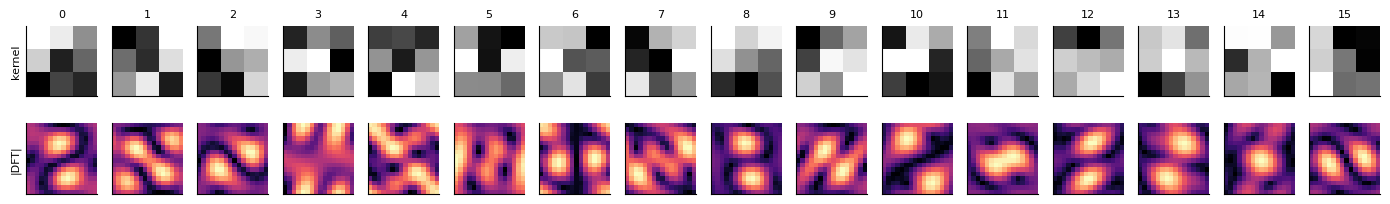

|DFT| at zero frequency / maximum of |DFT| per kernel: [0.14 0.77 0.   0.52 0.56 0.73 0.02 0.69 0.29 0.65 0.06 0.97 0.31 0.48
 1.   0.03]


In [34]:
NF = 16
spec = np.abs(np.fft.fftshift(np.fft.fft2(K, s=(NF, NF)), axes=(1, 2)))     # (16, 16, 16) |DFT| of padded kernels
freqs = np.fft.fftshift(np.fft.fftfreq(NF))                                   # cycles per pixel, -0.5 ... 0.4375
fig, axes = plt.subplots(2, 16, figsize=(14, 2.4))
show_kernels(axes[0], K, "gray")
for o, a in enumerate(axes[1]):
    a.imshow(spec[o], cmap="magma", extent=[freqs[0], freqs[-1], freqs[-1], freqs[0]]); a.set_xticks([]); a.set_yticks([])
    axes[0, o].set_title(f"{o}", fontsize=8)
axes[0, 0].set_ylabel("kernel", fontsize=8); axes[1, 0].set_ylabel("|DFT|", fontsize=8)
plt.tight_layout(); plt.show()
dc = spec[:, NF // 2, NF // 2] / spec.reshape(16, -1).max(1)                  # zero-frequency share
print("|DFT| at zero frequency / maximum of |DFT| per kernel:", np.round(dc, 2))

Several trained kernels are close to the Sobel kernels: kernel 8 has $\cos(W,G_y)=+0.85$ and kernel 12 has $\cos(W,G_y)=-0.84$ (horizontal-edge detectors of both signs), kernel 15 has $\cos(W,G_x)=-0.79$ and kernel 6 $\cos(W,G_x)=-0.72$ (vertical-edge detectors), all with nearly zero mean. Their Fourier magnitudes nearly vanish at zero frequency (ratio 0.02 for kernel 6, 0.03 for kernel 15) and show two lobes along the direction across the edge. Other kernels are low-pass: kernel 14 has cosine 0.76 with the uniform kernel and kernel 11 0.65, and their Fourier magnitude is largest at or near zero frequency (ratio 1.00 and 0.97). The layer has thus split into edge detectors of several orientations and smoothing / brightness filters, without being told to.

### Input channels of the second layer

The second layer `conv2` has kernel shape $(3,3,16,32)$, i.e. $(32,16,3,3)$ in the PyTorch order: for every output channel $o$ and input channel $i$ there is one $3\times3$ slice $W[o,i]$. The matrix of norms $\|W[o,i]\|$ ($32\times16$) shows how strongly output channel $o$ reads input channel $i$, before and after training.

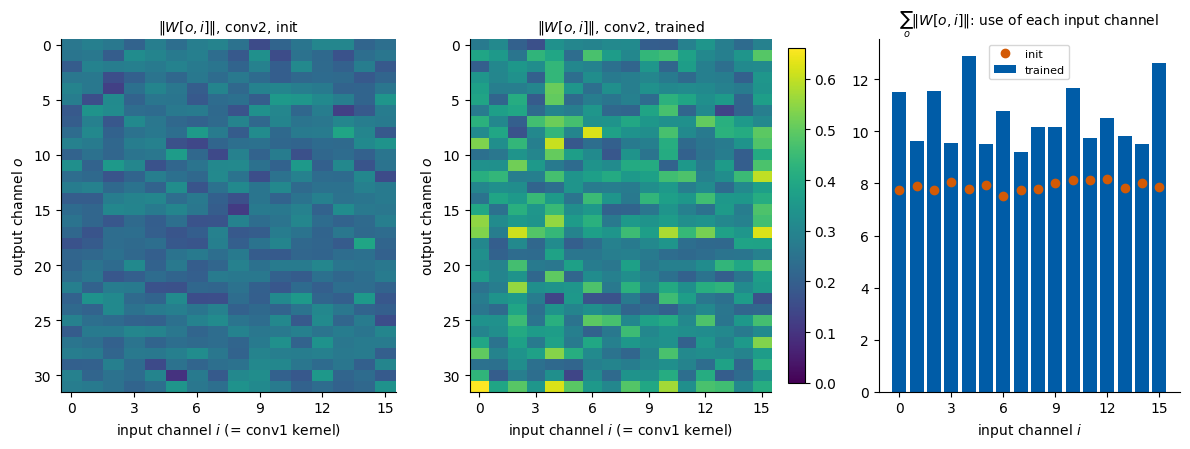

least used input channels (trained): [ 7  5 14]  with conv1 norms [1.52  1.197 1.488]
ratio of largest to smallest entry: init 4.0  trained 5.0


In [35]:
W2 = np.transpose(np.asarray(mnist_cnn.conv2.kernel[...]), (3, 2, 0, 1))          # (32, 16, 3, 3)
W2_init = np.transpose(mnist_init["conv2"]["kernel"], (3, 2, 0, 1))
N2, N2_init = np.linalg.norm(W2, axis=(2, 3)), np.linalg.norm(W2_init, axis=(2, 3))   # (32, 16)
assert N2.shape == (32, 16)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
vmax = N2.max()
for a, M, t in [(axes[0], N2_init, "init"), (axes[1], N2, "trained")]:
    im = a.imshow(M, cmap="viridis", vmin=0, vmax=vmax, aspect="auto"); a.set_title(f"$\\|W[o,i]\\|$, conv2, {t}", fontsize=10)
    a.set_xlabel("input channel $i$ (= conv1 kernel)"); a.set_ylabel("output channel $o$"); a.set_xticks(range(0, 16, 3))
plt.colorbar(im, ax=axes[1], fraction=0.05)
axes[2].bar(range(16), N2.sum(0), color=UJBlue, label="trained"); axes[2].plot(range(16), N2_init.sum(0), "o", color=DSOrange, label="init")
axes[2].set_xlabel("input channel $i$"); axes[2].set_xticks(range(0, 16, 3)); axes[2].set_title("$\\sum_o \\|W[o,i]\\|$: use of each input channel", fontsize=10); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("least used input channels (trained):", np.argsort(N2.sum(0))[:3], " with conv1 norms", np.round(norms[np.argsort(N2.sum(0))[:3]], 3))
print("ratio of largest to smallest entry: init", round(N2_init.max() / N2_init.min(), 1), " trained", round(N2.max() / N2.min(), 1))

At initialisation all entries of $\|W[o,i]\|$ are similar (largest/smallest = 4.0). After training the ratio is 5.0: in this run the second layer reads all its input channels with comparable strength, but the least used input channels are 7, 5 and 14, three of the low-pass kernels of Section 6 (cosine 0.41, 0.41 and 0.76 with the uniform kernel), and the most used are 4 and 15, an edge-like and a vertical-edge kernel. The second layer builds its features mainly from the edge maps. (Lab 013a, with a different initialisation, shows the same tendency more strongly.)

## 7. Feature maps

Flax has no forward hooks. A module is plain Python code, so the simplest way to see intermediate results is to have the forward pass return them: `CifarBody.activations(x)` returns a dictionary with the output of every ReLU (`act1`, `act2`, `act3`) and every pooling layer, and `__call__` itself uses this method. There is therefore only one implementation of the forward pass, and the intermediates cannot drift away from what the network computes. There are two alternatives: calling the submodules `conv1`, `bn1`, … one after another outside the module, which duplicates the forward code, or storing values with `self.sow(nnx.Intermediate, ...)` and collecting them with `nnx.pop(model, nnx.Intermediate)`.

Shapes for one image: `act1` $(1,32,32,32)$, `act2` $(1,16,16,64)$, `act3` $(1,8,8,128)$ (channels last).

In [36]:
LAYERS = ["act1", "act2", "act3"]
i_img = 7
regular.eval()                                                    # dropout off, running batch-norm statistics
acts = regular.body.activations(jnp.asarray(Xc_te[i_img:i_img + 1]))
logits = regular.head(acts["out"])
assert np.allclose(logits, regular(jnp.asarray(Xc_te[i_img:i_img + 1])), atol=1e-5)
for n in LAYERS: print(f"{n:5s} {acts[n].shape}  spatial size {acts[n].shape[1]}x{acts[n].shape[2]}")
print("true class:", CLASSES[yc_te[i_img]], "| predicted:", CLASSES[int(logits.argmax())])

act1  (1, 32, 32, 32)  spatial size 32x32
act2  (1, 16, 16, 64)  spatial size 16x16
act3  (1, 8, 8, 128)  spatial size 8x8
true class: frog | predicted: frog


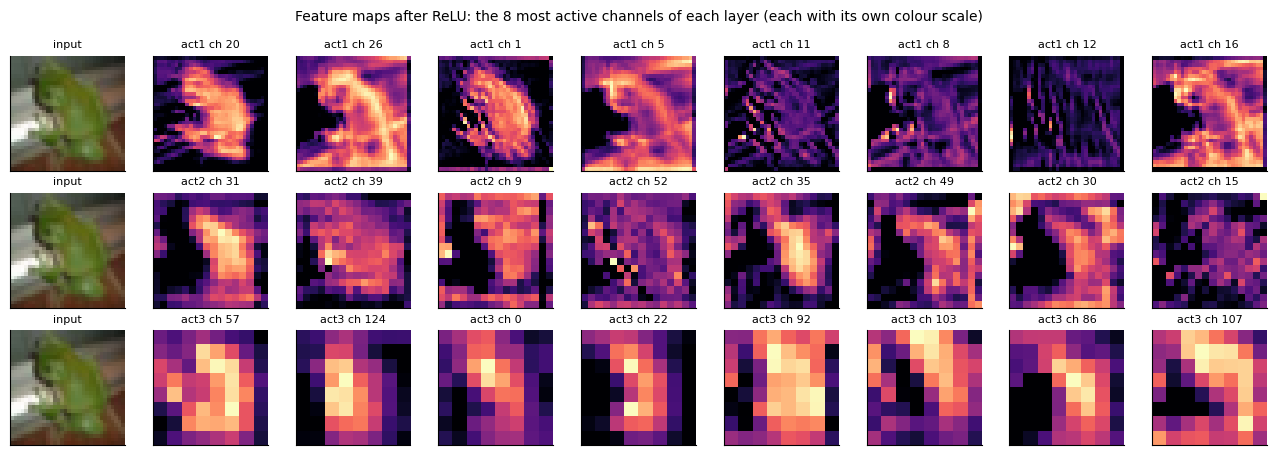

act1: fraction of zero activations 0.49
act2: fraction of zero activations 0.54


act3: fraction of zero activations 0.52


In [37]:
fig, axes = plt.subplots(3, 9, figsize=(13, 4.6))
for r, n in enumerate(LAYERS):
    axes[r, 0].imshow(Xc_te_raw[i_img]); axes[r, 0].set_title("input", fontsize=8)
    A = np.asarray(acts[n][0])                                     # (H, W, C)
    top = np.argsort(A.mean(axis=(0, 1)))[::-1][:8]                # the 8 channels with the largest mean activation
    for c, ch in enumerate(top):
        axes[r, c + 1].imshow(A[:, :, ch], cmap="magma"); axes[r, c + 1].set_title(f"{n} ch {ch}", fontsize=8)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
fig.suptitle("Feature maps after ReLU: the 8 most active channels of each layer (each with its own colour scale)", fontsize=10)
plt.tight_layout(); plt.show()
for n in LAYERS:
    print(f"{n}: fraction of zero activations {float((acts[n][0] == 0).mean()):.2f}")

The `act1` maps ($32\times32$) are still images of the frog: some channels respond to its surface, others to thin edges in particular directions. In `act2` ($16\times16$) the maps become coarser and mark regions rather than edges, and in `act3` ($8\times8$) each map is a blob of 64 numbers, mostly over the frog, which a $18\times18$-pixel receptive field per unit allows. About half of all activations are exactly zero after the ReLU (49%, 54% and 52%): each channel is active only where its pattern is present.

## 8. Images and classes that activate a channel

### Receptive field

A unit of `act3` at position $(r,c)$ of the $8\times8$ map depends only on a square window of the input, its **receptive field**. Going through the layers, the window size $R$ and the distance $J$ (in input pixels) between neighbouring units grow as
$$R_\ell = R_{\ell-1} + (k_\ell-1)\,J_{\ell-1},\qquad J_\ell = J_{\ell-1}\,s_\ell,\qquad R_0 = J_0 = 1, \tag{22}$$
for a layer with kernel (or pooling window) $k_\ell$ and stride $s_\ell$. For conv–pool–conv–pool–conv: $R = 3, 4, 8, 10, 18$ and $J = 1,1,2,2,4$. With padding 1, the window of unit $(r,c)$ covers input rows $4r-7,\dots,4r+10$ (and the same for columns), clipped to the image. We confirm this with the gradient of one unit with respect to the input, computed by `jax.grad`: pixels outside the window must have zero gradient.

In [38]:
R, J = 1, 1
for kind, k, s in [("conv1", 3, 1), ("pool1", 2, 2), ("conv2", 3, 1), ("pool2", 2, 2), ("conv3", 3, 1)]:
    R, J = R + (k - 1) * J, J * s
    print(f"after {kind}: receptive field {R:2d} pixels, jump {J}")
assert (R, J) == (18, 4)

def rf_window(r):                       # input rows (or columns) seen by act3 unit at row r, before clipping
    return 4 * r - 7, 4 * r + 10

r0, c0 = 4, 3
unit = lambda x: regular.body.activations(x)["act3"][0, r0, c0, :].sum()     # sum over channels
grad = np.asarray(jax.grad(unit)(jnp.asarray(Xc_te[i_img:i_img + 1])))[0]    # (32, 32, 3)
support = np.abs(grad).sum(-1) > 0                                           # pixels that influence the unit
rows, cols = np.flatnonzero(support.any(1)), np.flatnonzero(support.any(0))
lo_r, hi_r = rf_window(r0); lo_c, hi_c = rf_window(c0)
assert rows.min() >= max(lo_r, 0) and rows.max() <= min(hi_r, 31) and cols.min() >= max(lo_c, 0) and cols.max() <= min(hi_c, 31)
print(f"unit ({r0},{c0}): nonzero gradient in rows {rows.min()}..{rows.max()}, columns {cols.min()}..{cols.max()};"
      f" predicted window rows {lo_r}..{hi_r}, columns {lo_c}..{hi_c}")

after conv1: receptive field  3 pixels, jump 1
after pool1: receptive field  4 pixels, jump 2
after conv2: receptive field  8 pixels, jump 2
after pool2: receptive field 10 pixels, jump 4
after conv3: receptive field 18 pixels, jump 4


unit (4,3): nonzero gradient in rows 9..26, columns 5..22; predicted window rows 9..26, columns 5..22


### Top images of one channel and class selectivity

We pass the 10 000 test images through the regularised CNN once and keep, for every `act3` channel $k$ and image $n$: the maximum over positions,
$$a_{nk}=\max_{r,c} f_k(r,c), \tag{23}$$
its position, and the spatial mean. From the spatial means we form the class-mean matrix $\bar f_{ck}$ (average over the test images of class $c$), and for each channel a **selectivity index**
$$\text{SI}_k = \frac{\bar f_{\max,k} - \bar f_{\text{rest},k}}{\bar f_{\max,k} + \bar f_{\text{rest},k}}, \tag{24}$$
where $\bar f_{\max,k}$ is the largest class mean and $\bar f_{\text{rest},k}$ the mean over the other nine classes; $\text{SI}=0$ for a channel that responds equally to all classes, $\text{SI}=1$ for one that responds to a single class only. We show the channel with the largest index: its 9 test images with the largest $a_{nk}$, and the $18\times18$ receptive-field patch around the maximum.

In [39]:
@nnx.jit
def act3_stats(model, x):
    A = model.body.activations(x)["act3"]                 # (B, 8, 8, 128)
    flat = A.reshape(A.shape[0], 64, A.shape[-1])          # positions in row-major order r*8 + c
    return flat.max(1), flat.argmax(1), flat.mean(1)       # each (B, 128)

regular.eval()
out = [act3_stats(regular, jnp.asarray(Xc_te[k:k + 1000])) for k in range(0, 10000, 1000)]
amax, apos, amean = (np.concatenate([np.asarray(o[i]) for o in out]) for i in range(3))   # (10000, 128) each
class_mean = np.stack([amean[yc_te == c].mean(0) for c in range(10)])                    # (10, 128)
best = class_mean.max(0); rest = (class_mean.sum(0) - best) / 9
SI = (best - rest) / (best + rest + 1e-12)
ch = int(np.argmax(SI))
print("act3 activations:", amax.shape, "| channel", ch, "SI =", SI[ch].round(2), "| preferred class:", CLASSES[class_mean[:, ch].argmax()])
print("median SI over the 128 channels:", np.median(SI).round(2))

act3 activations: (10000, 128) | channel 124 SI = 0.52 | preferred class: frog
median SI over the 128 channels: 0.29


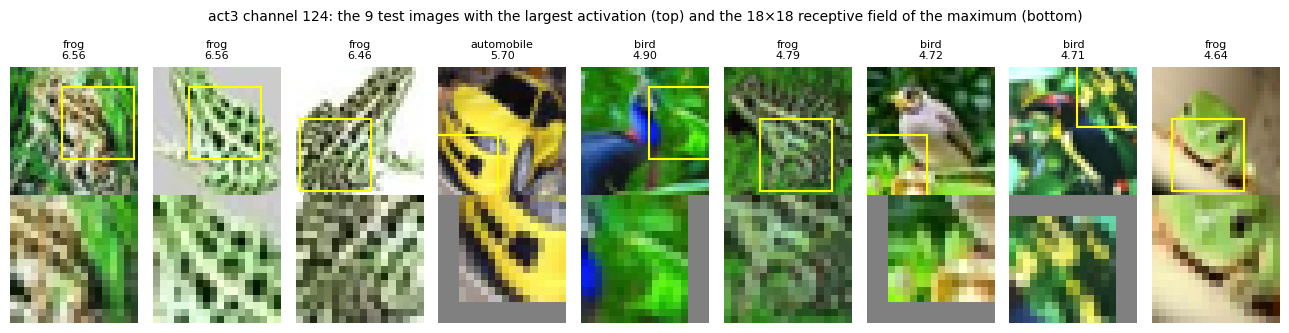

In [40]:
top9 = np.argsort(amax[:, ch])[::-1][:9]
PAD = 10
fig, axes = plt.subplots(2, 9, figsize=(13, 3.4))
for t, n in enumerate(top9):
    r, c = divmod(int(apos[n, ch]), 8)
    big = np.pad(Xc_te_raw[n], ((PAD, PAD), (PAD, PAD), (0, 0)), constant_values=128)   # grey outside the image
    lo_r, _ = rf_window(r); lo_c, _ = rf_window(c)
    patch = big[lo_r + PAD: lo_r + PAD + 18, lo_c + PAD: lo_c + PAD + 18]
    axes[0, t].imshow(Xc_te_raw[n]); axes[0, t].add_patch(plt.Rectangle((lo_c - 0.5, lo_r - 0.5), 18, 18, fill=False, ec="yellow", lw=1.5))
    axes[0, t].set_title(f"{CLASSES[yc_te[n]]}\n{amax[n, ch]:.2f}", fontsize=8); axes[1, t].imshow(patch)
for a in axes.ravel(): a.axis("off")
fig.suptitle(f"act3 channel {ch}: the 9 test images with the largest activation (top) and the 18×18 receptive field of the maximum (bottom)", fontsize=10)
plt.tight_layout(); plt.show()

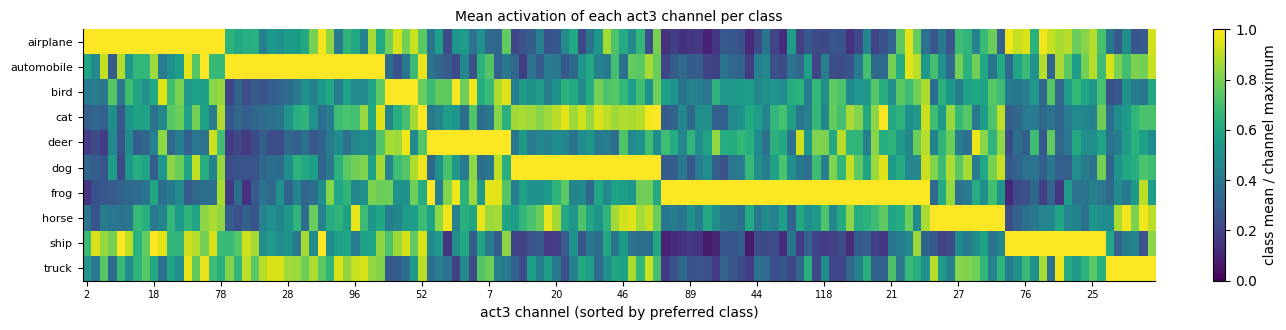

number of channels preferring each class: {'airplane': 17, 'automobile': 19, 'bird': 4, 'cat': 1, 'deer': 10, 'dog': 18, 'frog': 32, 'horse': 9, 'ship': 12, 'truck': 6}


In [41]:
cm_norm = class_mean / class_mean.max(0, keepdims=True)                 # each channel scaled to its largest class mean
order = np.lexsort((-SI, class_mean.argmax(0)))                         # group channels by preferred class
fig, ax = plt.subplots(figsize=(13, 3.4))
im = ax.imshow(cm_norm[:, order], aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=8); ax.set_xlabel("act3 channel (sorted by preferred class)")
ax.set_xticks(range(0, 128, 8)); ax.set_xticklabels(order[::8], fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.02, label="class mean / channel maximum"); ax.set_title("Mean activation of each act3 channel per class", fontsize=10)
plt.tight_layout(); plt.show()
print("number of channels preferring each class:", dict(zip(CLASSES, np.bincount(class_mean.argmax(0), minlength=10).tolist())))

The gradient confirms the receptive field: the unit at $(4,3)$ depends exactly on input rows 9–26 and columns 5–22, an $18\times18$ window. The most class-selective `act3` channel (124, SI = 0.52, median over channels 0.29) prefers frogs: 5 of its 9 strongest test images are frogs, and the patches show spotted or mottled green and grey skin; the others (a yellow car with black spots, birds in green foliage) share that texture. The channel has learned a texture, not a frog. The heat map shows that most channels have one preferred class but respond to related classes too (cat and dog share many channels); 32 channels prefer "frog" and only 1 "cat", so the representation is not spread evenly over the classes.

## 9. Class activation maps

### A network ending in global average pooling

A class activation map (CAM; B. Zhou et al., *Learning Deep Features for Discriminative Localization*, CVPR 2016, [arXiv:1512.04150](https://arxiv.org/abs/1512.04150)) needs a network whose last convolutional layer is followed by global average pooling (GAP) and one dense layer. Ours:

| layer | output shape |
|---|---|
| `conv1` $3\to32$, batch norm, ReLU, max pool | $(N,16,16,32)$ |
| `conv2` $32\to64$, batch norm, ReLU, max pool | $(N,8,8,64)$ |
| `conv3` $64\to128$, batch norm, ReLU → feature maps $f_k$ | $(N,8,8,128)$ |
| global average pooling → $F_k$ | $(N,128)$ |
| `fc`: dense $128\to10$ → class scores $z_c$ | $(N,10)$ |

### The class activation map formula

We use the notation of the lecture. Let $f_k(x,y)$ be the value of feature map $k=1,\dots,K$ ($K=128$) of the last convolutional layer at position $(x,y)$ of the $8\times8$ grid, with $N=64$ positions, and
$$F_k = \frac1N\sum_{x,y}f_k(x,y) \tag{25}$$
its global average. The dense layer has weights $w^c_k$ and biases $b_c$, from feature $k$ to class $c$ (in Flax `fc.kernel[k, c]` and `fc.bias[c]`, which is the notation $w_{k,c}$ of the previous lecture). It produces the score of class $c$ before the softmax and the probability of class $c$,
$$z_c=\sum_k w^c_k F_k + b_c,\qquad q_c=\frac{e^{z_c}}{\sum_j e^{z_j}}. \tag{26}$$

Inserting $F_k$ and exchanging the two finite sums,
$$z_c = \sum_k w^c_k\,\frac1N\sum_{x,y}f_k(x,y) + b_c = \frac1N\sum_{x,y}\underbrace{\sum_k w^c_k\,f_k(x,y)}_{M_c(x,y)} + b_c . \tag{27}$$
The **class activation map** $M_c(x,y)$ of equation (27), often written $\mathrm{CAM}_c$ with $A_k$ in place of $f_k$, says how much position $(x,y)$ contributes to the score of class $c$: positive values are evidence for the class, negative values against it. Its spatial mean is exactly $z_c-b_c$, which we confirm numerically. To overlay it on the $32\times32$ image, the $8\times8$ map is upsampled by bilinear interpolation and, for display, rescaled to $[0,1]$.

In [42]:
class GapBody(nnx.Module):
    def __init__(self, rngs):
        self.conv1, self.bn1 = nnx.Conv(3, 32, (3, 3), padding="SAME", rngs=rngs), nnx.BatchNorm(32, momentum=0.9, rngs=rngs)
        self.conv2, self.bn2 = nnx.Conv(32, 64, (3, 3), padding="SAME", rngs=rngs), nnx.BatchNorm(64, momentum=0.9, rngs=rngs)
        self.conv3, self.bn3 = nnx.Conv(64, 128, (3, 3), padding="SAME", rngs=rngs), nnx.BatchNorm(128, momentum=0.9, rngs=rngs)
    def __call__(self, x):
        h = nnx.max_pool(nnx.relu(self.bn1(self.conv1(x))), (2, 2), strides=(2, 2))
        h = nnx.max_pool(nnx.relu(self.bn2(self.conv2(h))), (2, 2), strides=(2, 2))
        return nnx.relu(self.bn3(self.conv3(h)))            # (N, 8, 8, 128): feature maps f_k(x, y)

class GapCNN(nnx.Module):
    def __init__(self, rngs):
        self.body, self.fc = GapBody(rngs), nnx.Linear(128, 10, rngs=rngs)
    def __call__(self, x):
        f = self.body(x)
        return self.fc(f.mean(axis=(1, 2)))                 # global average pooling F_k, then z_c

gap = GapCNN(nnx.Rngs(0))
print("parameters:", count_params(gap))
hist["GAP CNN"] = train(gap, Xc_tr, yc_tr, Xc_te, yc_te, EPOCHS_GAP, weight_decay=5e-4, use_augment=True, name="GAP CNN")
print("saved", save(gap, "gap_cnn"))

parameters: 94986


GAP CNN epoch 1/3: train acc 0.479, test acc 0.473, test loss 1.510  (84 s)


GAP CNN epoch 2/3: train acc 0.571, test acc 0.559, test loss 1.202  (153 s)


GAP CNN epoch 3/3: train acc 0.587, test acc 0.577, test loss 1.182  (209 s)
saved results/Lab_013b_gap_cnn.msgpack


Global average pooling does not appear in the table: it is the operation `f.mean(axis=(1, 2))` in `__call__`, not a submodule. The dense layer after it has
$$128\cdot10+10=1290 \tag{28}$$
parameters, against the $1\,049\,088$ of equation (18) in the first dense layer of the `CifarCNN` head.

In [43]:
print(nnx.tabulate(gap, jnp.zeros((1, 32, 32, 3)), console_kwargs=dict(width=110, color_system=None)))


GapCNN Summary                                                
┏━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ path       ┃ type      ┃ inputs             ┃ outputs            ┃ BatchStat          ┃ Param              ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│            │ GapCNN    │ float32[1,32,32,3] │ float32[1,10]      │ 448 (1.8 KB)       │ 94,986 (379.9 KB)  │
├────────────┼───────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ body       │ GapBody   │ float32[1,32,32,3] │ float32[1,8,8,128] │ 448 (1.8 KB)       │ 93,696 (374.8 KB)  │
├────────────┼───────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ body/conv1 │ Conv      │ float32[1,32,32,3] │ float32[1,32,32,3… │                    │ bias: float32[32]  │
│            │           │                    │                    │                    │ kernel:            │
│            │           │                    │                    │                    │ float32[3,3,3,32]  │
│            │           │                    │                    │                    │                    │
│            │           │                    │                    │                    │ 896 (3.6 KB)       │
├────────────┼───────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ body/bn1   │ BatchNorm │ float32[1,32,32,3… │ float32[1,32,32,3… │ mean: float32[32]  │ bias: float32[32]  │
│            │           │                    │                    │ var: float32[32]   │ scale: float32[32] │
│            │           │                    │                    │                    │                    │
│            │           │                    │                    │ 64 (256 B)         │ 64 (256 B)         │
├────────────┼───────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ body/conv2 │ Conv      │ float32[1,16,16,3… │ float32[1,16,16,6… │                    │ bias: float32[64]  │
│            │           │                    │                    │                    │ kernel:            │
│            │           │                    │                    │                    │ float32[3,3,32,64] │
│            │           │                    │                    │                    │                    │
│            │           │                    │                    │                    │ 18,496 (74.0 KB)   │
├────────────┼───────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ body/bn2   │ BatchNorm │ float32[1,16,16,6… │ float32[1,16,16,6… │ mean: float32[64]  │ bias: float32[64]  │
│            │           │                    │                    │ var: float32[64]   │ scale: float32[64] │
│            │           │                    │                    │                    │                    │
│            │           │                    │                    │ 128 (512 B)        │ 128 (512 B)        │
├────────────┼───────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ body/conv3 │ Conv      │ float32[1,8,8,64]  │ float32[1,8,8,128] │                    │ bias: float32[128] │
│            │           │                    │                    │                    │ kernel:            │
│            │           │                    │                    │                    │ float32[3,3,64,12… │
│            │           │                    │                    │                    │                    │
│            │           │                    │                    │                    │ 73,856 (295.4 KB)  │
├────────────┼───────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ body/bn3   │ BatchNorm │ float32[1,8,8,128] │ floa

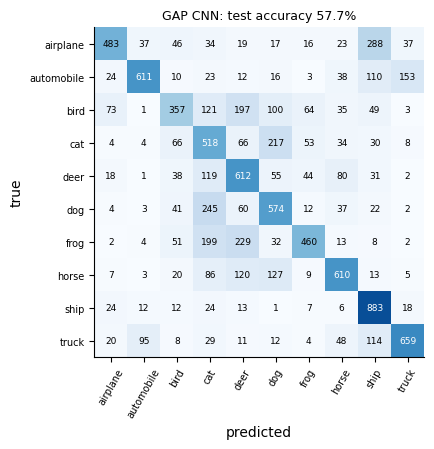

GAP CNN: 94986 parameters, train acc 58.7%, test acc 57.7%


In [44]:
pred_g = predict(gap, Xc_te).argmax(1)
cm_g = confusion_matrix(yc_te, pred_g)
fig, ax = plt.subplots(figsize=(5, 4.6))
plot_confusion(ax, cm_g, CLASSES, f"GAP CNN: test accuracy {100 * (pred_g == yc_te).mean():.1f}%"); plt.tight_layout(); plt.show()
print(f"GAP CNN: {count_params(gap)} parameters, train acc {100 * hist['GAP CNN']['train_acc'][-1]:.1f}%, test acc {100 * hist['GAP CNN']['test_acc'][-1]:.1f}%")

### The map of one image

For one image, `f = gap.body(x)` gives the feature maps $(1,8,8,128)$, `W = gap.fc.kernel[...]` is $(128,10)$ with the entries $W[k,c]$ equal to $w^c_k$, and the sum of equation (27) is one `einsum`. We assert that the mean of $M_c$ equals $z_c-b_c$ for every class. Bilinear upsampling is `jax.image.resize(..., method="bilinear")`.

In [45]:
def class_activation_maps(model, x):
    # x: (1, 32, 32, 3) -> maps M (10, 8, 8), scores z (10,)
    model.eval()
    f = model.body(x)[0]                                   # (8, 8, 128)
    W, b = model.fc.kernel[...], model.fc.bias[...]        # (128, 10), (10,)
    z = model(x)[0]                                        # (10,)
    M = jnp.einsum("kc,xyk->cxy", W, f)                    # M_c(x,y) = sum_k w^c_k f_k(x,y)
    assert np.allclose(M.mean(axis=(1, 2)), z - b, atol=1e-4), "spatial mean of M_c must equal z_c - b_c"
    return np.asarray(M), np.asarray(z)

def upsample(M, size=32):
    # bilinear interpolation of (C, 8, 8) maps to (C, size, size)
    return np.asarray(jax.image.resize(jnp.asarray(M), (M.shape[0], size, size), method="bilinear"))

M, z = class_activation_maps(gap, jnp.asarray(Xc_te[:1]))
print("M:", M.shape, " mean of M_c:", M.mean((1, 2)).round(3))
print("z_c - b_c:      ", (z - np.asarray(gap.fc.bias[...])).round(3))

M: (10, 8, 8)  mean of M_c: [-3.598 -2.973 -0.537  2.339 -0.735  1.367  1.416 -3.463 -1.01  -3.271]
z_c - b_c:       [-3.598 -2.973 -0.537  2.339 -0.735  1.367  1.416 -3.463 -1.01  -3.271]


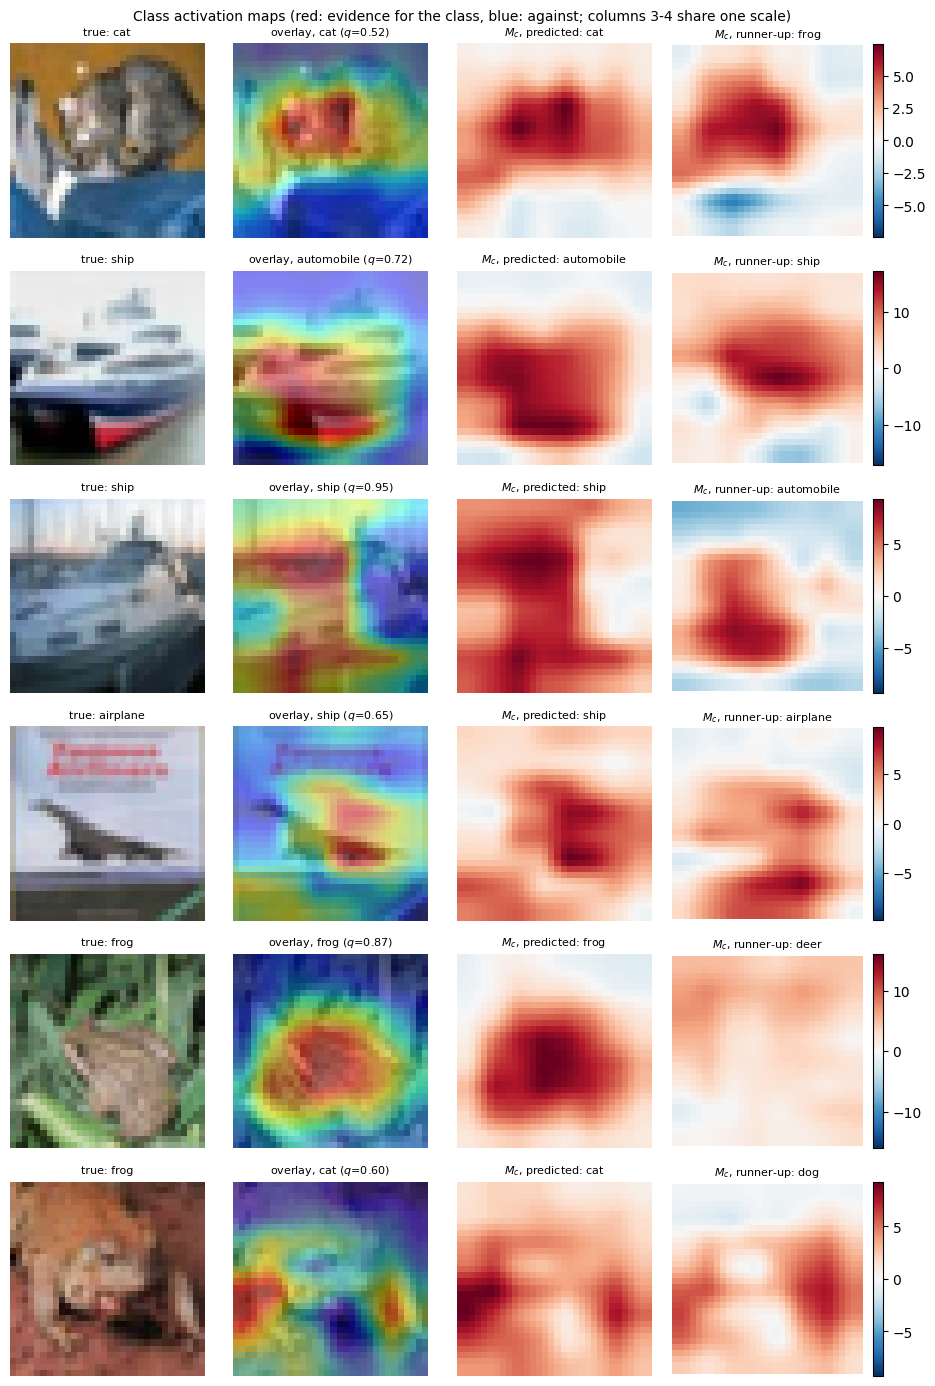

In [46]:
show = [0, 1, 2, 3, 4, 5]
fig, axes = plt.subplots(len(show), 4, figsize=(9.5, 2.35 * len(show)))
for r, n in enumerate(show):
    M, z = class_activation_maps(gap, jnp.asarray(Xc_te[n:n + 1]))
    q = np.exp(z - z.max()) / np.exp(z - z.max()).sum(); c_pred = int(z.argmax()); c_wrong = int(np.argsort(z)[::-1][1])   # runner-up
    U = upsample(M); lim = np.abs(U[[c_pred, c_wrong]]).max()
    Un = (U[c_pred] - U[c_pred].min()) / (U[c_pred].max() - U[c_pred].min())                                       # [0, 1] for the overlay
    axes[r, 0].imshow(Xc_te_raw[n]); axes[r, 0].set_title(f"true: {CLASSES[yc_te[n]]}", fontsize=8)
    axes[r, 1].imshow(Xc_te_raw[n]); axes[r, 1].imshow(Un, cmap="jet", alpha=0.45)
    axes[r, 1].set_title(f"overlay, {CLASSES[c_pred]} ($q$={q[c_pred]:.2f})", fontsize=8)
    for a, c, lab in [(axes[r, 2], c_pred, "predicted"), (axes[r, 3], c_wrong, "runner-up")]:
        im = a.imshow(U[c], cmap="RdBu_r", vmin=-lim, vmax=lim); a.set_title(f"$M_c$, {lab}: {CLASSES[c]}", fontsize=8)
    plt.colorbar(im, ax=axes[r, 3], fraction=0.046)
for a in axes.ravel(): a.axis("off")
fig.suptitle("Class activation maps (red: evidence for the class, blue: against; columns 3-4 share one scale)", fontsize=10)
plt.tight_layout(); plt.show()

The GAP CNN reaches 58.7% / 57.7% after 3 epochs (95 000 parameters). The assertion holds for every image: the spatial mean of $M_c$ equals $z_c-b_c$ to numerical precision, as the exchange of sums requires. For the correctly classified cat, ship and first frog the map of the predicted class lies on the object and the background contributes little or negative evidence. The misclassified images show how a CAM helps to diagnose errors: the ship predicted as "automobile" ($q=0.72$) has its "automobile" evidence on the hull, and the airplane predicted as "ship" has its "ship" evidence on the aircraft and the horizontal band below it; the runner-up map (the true class "airplane") lies on the same aircraft. The network looks at the right place but weighs the features wrongly.

## 10. Transfer learning from CIFAR-10 to MNIST

A network trained on one data set can be reused on another: its convolutional body has learned general-purpose filters, and only a new head must be trained. This is the usual recipe when one's own labelled data set is small. We take the **body of the regularised CIFAR-10 CNN** (Section 4) and train a new head on a few labelled MNIST digits.

### Input adaptation

The body expects inputs like the CIFAR-10 training images: 3 channels, $32\times32$ pixels, standardised with the CIFAR-10 means $\mu_c$ and standard deviations $\sigma_c$. An MNIST image $(28,28)$ with values in $[0,1]$ is brought into this form in three moves. First we pad 2 zero pixels on each side, giving $(32,32)$. MNIST digits already sit in a black frame, so zero padding keeps the stroke width (about 2–3 pixels) unchanged, whereas resizing $28\to32$ would interpolate and slightly thicken the strokes; both are reasonable. Next we repeat the grey channel three times, giving $(32,32,3)$, a grey RGB image. Finally we standardise with the **CIFAR-10** $\mu_c,\sigma_c$, not with MNIST statistics, because the first-layer kernels and the batch-norm running averages were fitted to inputs on that scale.

In [47]:
def mnist_as_cifar(X28):
    # X28: (N, 28, 28) in [0, 1] -> (N, 32, 32, 3) standardised with the CIFAR-10 statistics
    X = np.pad(X28, ((0, 0), (2, 2), (2, 2)))                  # (N, 32, 32), zeros = black
    X = np.repeat(X[..., None], 3, axis=-1)                    # (N, 32, 32, 3)
    return ((X - CIFAR_MEAN) / CIFAR_STD).astype(np.float32)

Xt_tr, Xt_te = mnist_as_cifar(Xm_tr), mnist_as_cifar(Xm_te)
assert Xt_tr.shape == (60000, 32, 32, 3)
print("adapted MNIST:", Xt_tr.shape, "| value of a black pixel per channel:", Xt_tr[0, 0, 0].round(3))

adapted MNIST: (60000, 32, 32, 3) | value of a black pixel per channel: [-1.989 -1.98  -1.707]


### Three training schemes

The model is the body (output $(N,4,4,128)$, flattened to 2048) followed by a new head: dense $2048\to128$, ReLU, dense $128\to10$. We train it in three ways.

In scheme **(a), frozen body and new head**, gradients and updates are taken only with respect to the parts we select, which in JAX is done with a **filter**. `HEAD = nnx.All(nnx.Param, nnx.PathContains("head"))` selects the parameters whose path contains `head`; `nnx.value_and_grad(..., argnums=nnx.DiffState(0, HEAD))` differentiates only with respect to them, and `nnx.Optimizer(model, optax.adam(1e-3), wrt=HEAD)` holds optimiser state and applies updates only to them. In addition the body stays in evaluation mode during training: otherwise batch normalisation would still overwrite its running statistics (they are not parameters, but they are updated in every training-mode forward pass) and dropout would be active. We copy all body variables (parameters and batch statistics) before training and assert afterwards that nothing changed.

Scheme **(b)** trains the same architecture with a randomly initialised body, everything trained (the entry `"random"` of `METHODS`). Scheme **(c), fine-tuning**, starts from the CIFAR-10 body and trains everything, with a smaller learning rate for the body ($10^{-4}$) than for the new head ($10^{-3}$). `optax.multi_transform` applies a different optimiser to each group of parameters, and a function assigns the label `"body"` or `"head"` to each parameter from its path. The small rate adapts the pretrained filters without destroying them.

Each scheme is trained on $n$ labelled MNIST images per class, $n\in\{10,100,1000\}$ (100, 1000 and 10 000 images; the classes are balanced), with `TRANSFER_STEPS` mini-batches of 64 images drawn at random from the subset, and tested on all 10 000 MNIST test images. For comparison, Section 3 used all 60 000 training images.

In [48]:
class TransferHead(nnx.Module):
    def __init__(self, rngs):
        self.fc1, self.fc2 = nnx.Linear(2048, 128, rngs=rngs), nnx.Linear(128, 10, rngs=rngs)
    def __call__(self, h):
        return self.fc2(nnx.relu(self.fc1(h.reshape(h.shape[0], -1))))

class TransferNet(nnx.Module):
    def __init__(self, body, rngs):
        self.body, self.head = body, TransferHead(rngs)
    def __call__(self, x):
        return self.head(self.body(x))

HEAD = nnx.All(nnx.Param, nnx.PathContains("head"))          # filter: parameters of the new head

def body_or_head(params):
    # label every parameter "head" or "body" from its path, for optax.multi_transform
    return jax.tree_util.tree_map_with_path(lambda path, _: "head" if any(getattr(p, "key", None) == "head" for p in path) else "body", params)

def make_model(method, seed=0):
    rngs = nnx.Rngs(params=seed, dropout=seed + 1)
    if method == "random":
        return TransferNet(CifarBody(True, rngs), rngs)            # random body
    return TransferNet(nnx.clone(regular.body), rngs)              # copy of the trained CIFAR-10 body

def make_optimizer(model, method):
    if method == "frozen":
        return nnx.Optimizer(model, optax.adam(1e-3), wrt=HEAD)    # optimiser state and updates only for the head
    if method == "random":
        return nnx.Optimizer(model, optax.adam(1e-3), wrt=nnx.Param)
    tx = optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(1e-3)}, body_or_head)
    return nnx.Optimizer(model, tx, wrt=nnx.Param)

@nnx.jit
def train_step_head(model, optimizer, x, y):
    loss, grads = nnx.value_and_grad(loss_fn, argnums=nnx.DiffState(0, HEAD))(model, x, y)   # gradients for the head only
    optimizer.update(model, grads)
    return loss

def fit_steps(model, method, X, y, steps=TRANSFER_STEPS, batch=64, seed=0):
    opt = make_optimizer(model, method); r = np.random.default_rng(seed)
    model.train()
    if method == "frozen": model.body.eval()                      # batch norm keeps the CIFAR statistics, no dropout
    step = train_step_head if method == "frozen" else train_step
    for t in range(steps):
        idx = r.integers(0, len(X), batch)
        step(model, opt, jnp.asarray(X[idx]), jnp.asarray(y[idx]))
    return model

def balanced_subset(y, n_per_class, seed=0):
    r = np.random.default_rng(seed)
    return np.concatenate([r.choice(np.flatnonzero(y == c), n_per_class, replace=False) for c in range(10)])

m_test = make_model("frozen")
n_head = sum(x.size for x in jax.tree.leaves(nnx.state(m_test, HEAD)))
print("trainable parameters (a) frozen:", n_head, "of", count_params(m_test), "| (b), (c): all", count_params(m_test))
print("labels for multi_transform (first layers):", {k: body_or_head(nnx.to_pure_dict(nnx.state(m_test, nnx.Param)))[k]["fc1" if k == "head" else "conv1"]
                                                     for k in ("body", "head")})

trainable parameters (a) frozen: 263562 of 357258 | (b), (c): all 357258
labels for multi_transform (first layers): {'body': {'bias': 'body', 'kernel': 'body'}, 'head': {'bias': 'head', 'kernel': 'head'}}


In [49]:
METHODS = {"frozen": "(a) frozen CIFAR-10 body + new head", "random": "(b) random initialisation", "finetune": "(c) fine-tuning, smaller rate for the body"}
BUDGETS = [10, 100, 1000]
acc_tl, final_tl = {m: [] for m in METHODS}, {}
t0 = time.time()
for n in BUDGETS:
    sub = balanced_subset(ym_tr, n)
    for m in METHODS:
        model = make_model(m)
        body_before = jax.tree.map(np.array, nnx.to_pure_dict(nnx.state(model.body, (nnx.Param, nnx.BatchStat))))
        fit_steps(model, m, Xt_tr[sub], ym_tr[sub])
        if m == "frozen":
            after = jax.tree.map(np.array, nnx.to_pure_dict(nnx.state(model.body, (nnx.Param, nnx.BatchStat))))
            assert all(np.array_equal(u, v) for u, v in zip(jax.tree.leaves(body_before), jax.tree.leaves(after))), "frozen body changed"
            checksum = lambda d: sum(float(np.abs(v.astype(np.float64)).sum()) for v in jax.tree.leaves(d))
            print(f"   frozen body unchanged: checksum before {checksum(body_before):.6f}, after {checksum(after):.6f}")
        acc = float((predict(model, Xt_te).argmax(1) == ym_te).mean())
        acc_tl[m].append(acc); final_tl[m] = model
        print(f"n = {n:4d} per class | {METHODS[m]:45s} test accuracy {100 * acc:5.1f}%  ({time.time() - t0:.0f} s)")

   frozen body unchanged: checksum before 4290.107254, after 4290.107254


n =   10 per class | (a) frozen CIFAR-10 body + new head           test accuracy  86.8%  (4 s)


n =   10 per class | (b) random initialisation                     test accuracy  88.1%  (21 s)


n =   10 per class | (c) fine-tuning, smaller rate for the body    test accuracy  88.6%  (37 s)


   frozen body unchanged: checksum before 4290.107254, after 4290.107254


...

n =  100 per class | (c) fine-tuning, smaller rate for the body    test accuracy  95.3%  (72 s)


   frozen body unchanged: checksum before 4290.107254, after 4290.107254


n = 1000 per class | (a) frozen CIFAR-10 body + new head           test accuracy  96.3%  (75 s)


n = 1000 per class | (b) random initialisation                     test accuracy  96.7%  (90 s)


n = 1000 per class | (c) fine-tuning, smaller rate for the body    test accuracy  96.6%  (103 s)


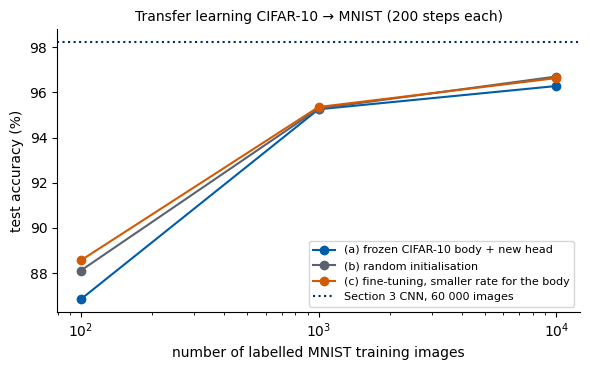

In [50]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for (m, lab), c in zip(METHODS.items(), [UJBlue, UJGray, DSOrange]):
    ax.plot(np.array(BUDGETS) * 10, 100 * np.array(acc_tl[m]), "o-", color=c, label=lab)
ax.axhline(100 * hist["MNIST CNN"]["test_acc"][-1], color=UJNavy, ls=":", label="Section 3 CNN, 60 000 images")
ax.set_xscale("log"); ax.set_xlabel("number of labelled MNIST training images"); ax.set_ylabel("test accuracy (%)")
ax.set_title(f"Transfer learning CIFAR-10 → MNIST ({TRANSFER_STEPS} steps each)", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

saved results/Lab_013b_transfer_frozen_1000_per_class.msgpack


saved results/Lab_013b_transfer_random_1000_per_class.msgpack


saved results/Lab_013b_transfer_finetune_1000_per_class.msgpack


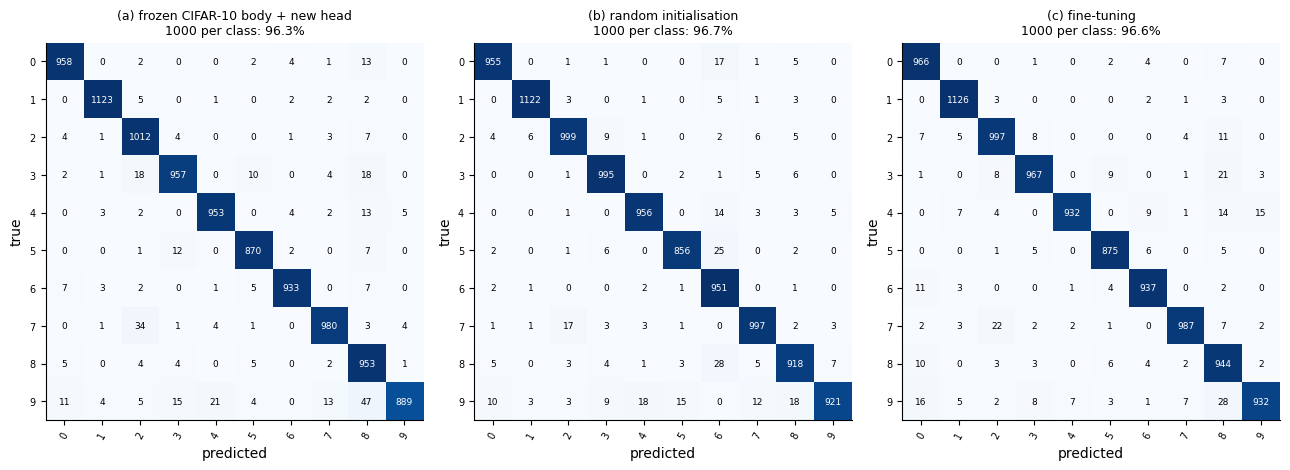

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for a, m in zip(axes, METHODS):
    pred = predict(final_tl[m], Xt_te).argmax(1)
    plot_confusion(a, confusion_matrix(ym_te, pred), [str(d) for d in range(10)],
                   f"{METHODS[m].split(',')[0]}\n{BUDGETS[-1]} per class: {100 * (pred == ym_te).mean():.1f}%")
    print("saved", save(final_tl[m], f"transfer_{m}_{BUDGETS[-1]}_per_class"))
plt.tight_layout(); plt.show()

All three schemes reach 87–89% with 10 digits per class and 96–97% with 1000 per class (Section 3, with all 60 000 images: 98.2%). The frozen CIFAR-10 body with a new head is within 1–2 points of the other two at every budget (86.8%, 95.2%, 96.3%), although its convolutions never saw a digit: the first layers compute generic local features (edges, blobs, contrast) that are useful for digits too, and the assertion confirms that only the head changed. It is, however, not better than training from random initialisation here (88.1%, 95.3%, 96.7%), and fine-tuning (88.6%, 95.3%, 96.6%) ends about where training from random initialisation ends. There are two reasons. MNIST is easy, so 100 labelled digits suffice to train a small CNN from random initialisation; and the deeper CIFAR-10 channels encode colour and texture (Section 8: frog skin) that have no meaning for white strokes on black. Transfer pays most when the labelled target set is small and the source data resemble the target (e.g. a network pretrained on many microscopy images reused for a new cell type). The recipe is the same as here: adapt the input to what the body expects, freeze the body (and its batch-norm statistics), train a new head, then optionally fine-tune with a small learning rate.

## 11. PyTorch and JAX equivalents

The table collects the PyTorch and JAX forms of the operations used in Labs 013a and 013b, so that code from one notebook can be translated into the other.

| task | PyTorch | JAX with Flax (`flax.nnx`) |
|---|---|---|
| image layout | $(N, C, H, W)$ | $(N, H, W, C)$ |
| convolution call | `F.conv2d(x, w, padding=1, stride=1)` | `jax.lax.conv_general_dilated(x, w, (1,1), [(1,1),(1,1)], dimension_numbers=("NHWC","HWIO","NHWC"))` |
| conv kernel shape | `conv.weight`: $(C_{\text{out}}, C_{\text{in}}, k_h, k_w)$ | `conv.kernel`: $(k_h, k_w, C_{\text{in}}, C_{\text{out}})$ |
| dense weight shape | `fc.weight`: $(n_{\text{out}}, n_{\text{in}})$ | `fc.kernel`: $(n_{\text{in}}, n_{\text{out}})$ |
| a layer's weights by name | `model.get_submodule("body.conv1").weight` | `model.body.conv1.kernel[...]` |
| list all parameters | `model.named_parameters()` | `nnx.state(model, nnx.Param)` |
| intermediate activations | `layer.register_forward_hook(fn)`, then `handle.remove()` | call the submodules one after another and keep the outputs |
| count parameters | `sum(p.numel() for p in model.parameters())` | `sum(x.size for x in jax.tree.leaves(nnx.state(model, nnx.Param)))` |
| training / evaluation mode | `model.train()`, `model.eval()` | `model.train()`, `model.eval()` |
| freeze a part | `p.requires_grad = False`; optimiser on the other parameters | `nnx.Optimizer(model, tx, wrt=filter)` and `nnx.DiffState(0, filter)` in `nnx.grad` |
| different learning rates | optimiser parameter groups | `optax.multi_transform` with labels per parameter |
| L2 weight decay (coupled) | `torch.optim.Adam(..., weight_decay=wd)` | `optax.chain(optax.add_decayed_weights(wd), optax.adam(lr))` |
| save weights | `torch.save(model.state_dict(), path)` | `flax.serialization.msgpack_serialize(nnx.to_pure_dict(nnx.state(model, (nnx.Param, nnx.BatchStat))))` |
| load weights | `model.load_state_dict(torch.load(path))` | `nnx.replace_by_pure_dict(state, msgpack_restore(bytes))`; `nnx.update(model, state)` |

In [52]:
# check: reload one saved model and compare the predictions
reloaded = load(CifarCNN(True, nnx.Rngs(params=42, dropout=43)), os.path.join(RESULTS, "Lab_013b_regularised_cnn.msgpack"))
assert np.allclose(predict(reloaded, Xc_te[:500]), predict(regular, Xc_te[:500]), atol=1e-5)
print("reloaded weights reproduce the predictions.")
print(f"total run time of the notebook: {(time.time() - T_START) / 60:.1f} min")

reloaded weights reproduce the predictions.
total run time of the notebook: 15.1 min
